# Objectif 
L'objectif est d'illustrer la structure en damier observée sur les figures d'ambiguïté obtenues avec gamma. 

Pour ce faire, on considère l'intersection SN2 vs OE7.

Date de création : 05/11/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from misc import equivalent_celerity
from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


In [3]:
# ======================================================================================================================
# Import
# ======================================================================================================================
import os
import pandas as pd

from real_data_analysis.acouplane.src.acouplane_cst import (
    ACOUPLANE_PORTION_NC_ROOT_FPATH,
    ROOT_ACOUPLANE_PROCESSED_IMG_DIR,
)
from real_data_analysis.acouplane.src.acouplane_combination import (
    RCV_COMBINATION_METHODS,
    combination_intersection_positions,
    enumerate_rcv_combinations,
    format_rcv_combination,
    rcv_combination_records,
)
from real_data_analysis.acouplane.src.acouplane_console import (
    make_figure_saver,
    make_logger,
)
from real_data_analysis.acouplane.src.acouplane_conventions import (
    library_event_error_mode,
)
from real_data_analysis.acouplane.src.acouplane_event import (
    apply_mfp_strategy_to_portions,
    build_portion_event_from_active_section,
    build_portion_library,
    get_crossing_distance_m,
    library_event_crossing_distances,
)
from real_data_analysis.acouplane.src.acouplane_localization import (
    add_validity_column,
    best_rcv_pair_per_distance,
    pivot_error_summary,
    select_and_order_distance_types,
    summarize_localization_errors,
)
from real_data_analysis.acouplane.src.acouplane_plot_analysis import (
    plot_error_cdf,
    plot_metric_vs_n_rcv,
    plot_rcv_pair_performance_heatmaps,
)
from real_data_analysis.acouplane.src.acouplane_plot_event import (
    plot_library_and_event_map,
)
from real_data_analysis.acouplane.src.acouplane_plot_mfp import (
    ambiguity_figure_filename,
    plot_combined_intersection_ambiguity,
    plot_combined_intersection_gamma_comparison,
)
from real_data_analysis.acouplane.src.acouplane_portion_io import (
    list_stored_intersections,
    open_portion,
    section_name_of,
)

# Calcul des surfaces d'ambiguïté pour illustrer la problématique 

In [4]:
# ======================================================================================================================
# Constants
# ======================================================================================================================
portion_id = 5
ROOT_IMG_PORTION = os.path.join(
    ROOT_ACOUPLANE_PROCESSED_IMG_DIR, f"portion{portion_id}"
)
ROOT_IMG_PORTION_RESULTS_TEST = os.path.join(ROOT_IMG_PORTION, "results_test_section")
os.makedirs(ROOT_IMG_PORTION_RESULTS_TEST, exist_ok=True)

portion_fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"


# Reference receiver of the pairs (rcv_i, reference_rcv): the same for the library and for the test section
reference_rcv = "obs1"

# Receivers that can be used (the reference receiver is ignored). None -> all the receivers of the portion
obs_ids = [
    "obs1",
    "obs2",
    "obs4",
    "obs7",
    "obs5",
    "obs6",
]

# Frequency band of the features
fmin = 10
fmax = 100

# Estimation of the RTF (pi_ij), chosen separately for the library and for the event
#   "spectral_ratio" -> S_ij / S_jj (active case)
#   "cs_evd"         -> first eigenvector of the spatial covariance matrix (preferable for passive signals)
# The two can differ (e.g. library: "spectral_ratio", passive event: "cs_evd")
library_rtf_method = "spectral_ratio"
event_rtf_method = "spectral_ratio"

# Test sections: each of them is removed from the library in turn and localized (its own run, with the library
# made of the other sections)
test_sections = ["sn2"]
# test_sections = ["sn0", "sn2", "oe7"]

# Sections that can be part of the library (None -> all the sections of the portion). The test section of the
# current run is always removed from it
# library_sections = None
library_sections = ["oe7"]

# Position error of the estimated intersection with respect to the theoretical one
#   "library" -> error between the library samples (position along the library section)
#   "event"   -> error between the samples of the test section (position along the test section)
#   "both"    -> sqrt(error_library**2 + error_test**2)
error_mode = "both"
success_threshold_m = (
    100  # an intersection is successfully localized if its error <= threshold [m]
)

# The theoretical intersection only exists if the test section crosses the library section: the library sections
# whose closest samples are further apart than this distance are not compared to the test section
max_crossing_distance_m = 200

# Approach used to combine the receivers and combinations to study
#   "mean_surfaces" -> mean of the ambiguity surfaces of the combined receiver pairs
combination_method = "mean_surfaces"
#   rcv_combinations = None  -> all the combinations of the sizes `combination_sizes` among the receivers
#   rcv_combinations = [["obs2"], ["obs2", "obs4"], ...] -> explicit combinations
rcv_combinations = None
combination_sizes = (
    None  # None -> all sizes, from 1 receiver to all of them; e.g. [1, 2, 5]
)
max_combinations = 200  # safety limit on the number of combinations (the number grows as 2**n_receivers)

# Distance types to analyse: None -> all those computed, otherwise a list among "theta", "theta_gamma", "L2_gamma",
# "dcf", "theta_gamma_centered", "L2_gamma_centered" (the centered ones need compare_centered_gamma = True)
distance_types_to_analyse = None

# Contrast of the ambiguity surface = (P - min) / P, P being the percentile `contrast_percentile` of the surface
contrast_percentile = 50

# Ambiguity surfaces
#   combinations_to_plot = None -> all the combinations studied
# combinations_to_plot = [["obs2"], ["obs4"]] -> only these combinations
combinations_to_plot = [["obs2"], ["obs4"], ["obs7"], ["obs5"], ["obs6"]]
# Metrics displayed next to the real distance (always in the first panel): 3 among
# "theta", "theta_gamma", "L2_gamma", "dcf", "theta_gamma_centered", "L2_gamma_centered"
# (the centered ones need compare_centered_gamma = True), e.g. ["theta_gamma_centered", "L2_gamma_centered", "dcf"]
ambiguity_metrics = ["dcf", "theta_gamma", "L2_gamma"]
ambiguity_cmap = "Grays_r"
ambiguity_max_quantile = (
    0.95  # quantile of each feature distance used as upper bound of its color scale
)
ambiguity_d_real_vmax = 200  # upper bound of the color scale of the real distance [m]
max_ambiguity_figures = (
    200  # safety limit on the number of figures (comparisons x combinations)
)

# ======================================================================================================================
# Booleans to control behavior
# ======================================================================================================================
# Also compute the gamma distances with gamma centered along frequency
compare_centered_gamma = True
# Save the theoretical and estimated intersections (positions) of every comparison and combination (CSV)
save_intersection_positions = False

# Figures
plot_map = False
plot_ambiguity = True
plot_gamma_comparison = True

# Analysis of the combinations
analyse_error_vs_n_rcv = False
analyse_contrast_vs_n_rcv = False
analyse_combination_performance = False
verbose = True

# ======================================================================================================================
# Console messages and figure saving
# ======================================================================================================================
log = make_logger(portion_id, verbose)
save_test_figure = make_figure_saver(ROOT_IMG_PORTION_RESULTS_TEST, log)

# ======================================================================================================================
# Check the settings right away (before any heavy computation)
# ======================================================================================================================
position_error_mode = library_event_error_mode(error_mode)
if combination_method not in RCV_COMBINATION_METHODS:
    raise ValueError(
        f"Unknown combination_method '{combination_method}'. Valid methods: "
        f"{list(RCV_COMBINATION_METHODS)}."
    )
if not 0 < contrast_percentile < 100:
    raise ValueError(
        f"contrast_percentile must be in ]0, 100[ (got {contrast_percentile})."
    )
if not test_sections:
    raise ValueError("test_sections is empty: give at least one section to localize.")

In [5]:

# ======================================================================================================================
# Load data (lazy: nothing is read in memory until values are actually used)
# ======================================================================================================================
log(f"Step 1 - Opening the portion {portion_id} (lazy, not loaded in memory)")
portion = open_portion(portion_fpath)

if "feature" not in portion.children:
    raise RuntimeError(
        f"No 'feature' group in '{portion_fpath}': the CPSD has never been computed for this "
        "portion. Compute it with acouplane_analyse_portion_generate_diag_all_intersections.py "
        "(compute_cpsds = True, save_modification_to_portion = True)."
    )

# Check the sections right away
available_sections = list(portion.feature.children)
unknown_sections = [name for name in test_sections if name not in available_sections]
if unknown_sections:
    raise ValueError(
        f"Unknown test section(s) {unknown_sections} (sections of the portion: {available_sections})."
    )
if library_sections is not None:
    unknown_sections = [
        name for name in library_sections if name not in available_sections
    ]
    if unknown_sections:
        raise ValueError(
            f"Unknown library section(s) {unknown_sections} (sections of the portion: {available_sections})."
        )
library_pool = (
    available_sections if library_sections is None else list(library_sections)
)

[Portion 5] Step 1 - Opening the portion 5 (lazy, not loaded in memory)


## Intersection étudiée 

Text(0, 0.5, 'Latitude [°]')

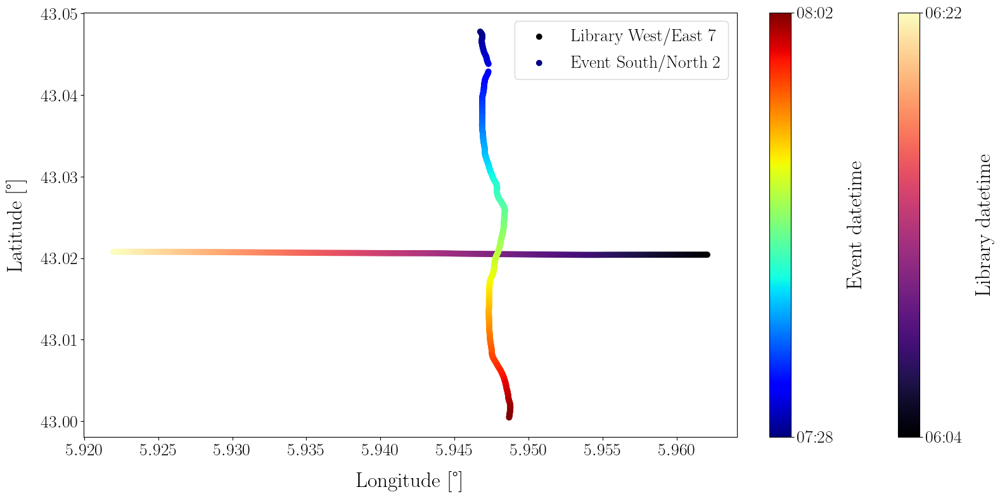

In [6]:
ds_pos_section = portion.position.oe7.to_dataset()

dates = ds_pos_section.src_datetime.values
date_num = mdates.date2num(dates)

sc = plt.scatter(
    ds_pos_section.tir_src_lon,
    ds_pos_section.tir_src_lat,
    c=date_num,
    cmap="magma",
    label=f"Library {ds_pos_section.attrs['section_orientation']} {ds_pos_section.attrs['section_id']}",
)
# plt.colorbar(sc, label="Library", location="bottom")
cbar = plt.colorbar(sc, ax=plt.gca(), location="right")
cbar.set_label("Library datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

ds_pos_section = portion.position.sn2.to_dataset()
dates = ds_pos_section.src_datetime.values
date_num = mdates.date2num(dates)
sc =plt.scatter(
    ds_pos_section.tir_src_lon,
    ds_pos_section.tir_src_lat,
    c=date_num,
    cmap="jet",
    label=f"Event {ds_pos_section.attrs['section_orientation']} {ds_pos_section.attrs['section_id']}",
)
cbar = plt.colorbar(sc, ax=plt.gca(), location="right")
cbar.set_label("Event datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

plt.legend()
plt.xlabel("Longitude [°]")
plt.ylabel("Latitude [°]")

# dates = ds_pos.atl_datetime.values
# date_num = mdates.date2num(dates)

# sc = ax.scatter(
#     ds_pos.atl_lon,
#     ds_pos.atl_lat,
#     c=date_num,
#     cmap="magma",
# )

# plot_obs_pos(ds_pos, ax=ax)

# cbar = fig.colorbar(sc, ax=ax)
# cbar.set_label("ATL datetime")
# cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
# cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

In [19]:

# ======================================================================================================================
# Library of reference features (all the candidate sections, built once)
# ======================================================================================================================
log("Step 2 - Library of reference features built from the portion")
portion_library = build_portion_library(
    portion,
    sections=library_pool,
    rcv_ref=reference_rcv,
    fmin=fmin,
    fmax=fmax,
    acquisition_mode="active",
    verbose=verbose,
    rtf_method=library_rtf_method,
)
portion_library

[Portion 5] Step 2 - Library of reference features built from the portion
    Library section 'oe7' (active, RTF 'spectral_ratio')


<xarray.DataTree>
Group: /
│   Attributes:
│       description:         Library of reference features
│       acquisition_mode:    active
│       reference_receiver:  obs1
│       rtf_method:          spectral_ratio
├── Group: /position
│   └── Group: /position/oe7
│           Dimensions:   (datetime: 376)
│           Coordinates:
│             * datetime  (datetime) datetime64[ns] 3kB 2026-02-25T06:04:00.600098 ... 20...
│           Data variables:
│               lon       (datetime) float64 3kB 5.962 5.962 5.962 ... 5.923 5.922 5.922
│               lat       (datetime) float64 3kB 43.02 43.02 43.02 ... 43.02 43.02 43.02
│           Attributes:
│               description:            Localisation features
│               campagne:               ACOUPLANE
│               geodesic_frame:         WGS84
│               portion_id:             5
│               section_orientation:    West/East
│               section_id:             7
│               section_label:          oe7
│               obs_position:           OBS position corrected using LMS inversion.
│               obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
│               reference_receiver:     obs1
│               rtf_method:             spectral_ratio
│               acquisition_mode:       active
└── Group: /feature
    └── Group: /feature/oe7
            Dimensions:           (rcv_id_feature: 5, library_datetime: 376, freq: 369,
                                   rcv_id: 7)
            Coordinates:
              * rcv_id_feature    (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs6' 'obs7'
              * library_datetime  (library_datetime) datetime64[ns] 3kB 2026-02-25T06:04:...
              * freq              (freq) float64 3kB 10.01 10.25 10.5 ... 99.37 99.61 99.85
              * rcv_id            (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
            Data variables:
                pi_ij             (rcv_id_feature, library_datetime, freq) complex64 6MB ...
                gamma_ij          (rcv_id_feature, library_datetime, freq) float32 3MB 11...
                sij_scot          (rcv_id_feature, library_datetime, freq) complex64 6MB ...
                library_lon       (library_datetime) float64 3kB 5.962 5.962 ... 5.922 5.922
                library_lat       (library_datetime) float64 3kB 43.02 43.02 ... 43.02 43.02
                rcv_lon           (rcv_id) float64 56B ...
                rcv_lat           (rcv_id) float64 56B ...
                rcv_immersion     (rcv_id) int16 14B ...
            Attributes:
                description:            Localisation features
                campagne:               ACOUPLANE
                geodesic_frame:         WGS84
                portion_id:             5
                section_orientation:    West/East
                section_id:             7
                section_label:          oe7
                obs_position:           OBS position corrected using LMS inversion.
                obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
                reference_receiver:     obs1
                rtf_method:             spectral_ratio
                acquisition_mode:       active

In [20]:
# ======================================================================================================================
# Ambiguity surfaces between each test section and the library (without the test section)
# ======================================================================================================================
log(
    "Step 3 - Ambiguity surfaces between each test section and the library sections that cross it"
)
datasets_mfp = {}
crossing_records = []

test_section = test_sections[0]

log(f"Test section '{test_section}'", level=1)

# The test section plays the role of the event
portion_event = build_portion_event_from_active_section(
    portion,
    test_section,
    rcv_ref=reference_rcv,
    fmin=fmin,
    fmax=fmax,
    rtf_method=event_rtf_method,
)

# The test section is removed from the library
candidate_sections = [name for name in library_pool if name != test_section]
if not candidate_sections:
    raise RuntimeError(
        f"No library section left once the test section '{test_section}' is removed: "
        "add sections to library_sections."
    )

# Library sections that cross the test section (the others have no intersection to find)
crossing_distances = library_event_crossing_distances(
    portion_library, portion_event, library_sections=candidate_sections
)
crossing_sections = []
for record in crossing_distances:
    is_crossing = record["crossing_distance_m"] <= max_crossing_distance_m
    crossing_records.append(
        dict(
            test_section=test_section,
            library=record["library"],
            crossing_distance_m=record["crossing_distance_m"],
            analysed=is_crossing,
        )
    )
    log(
        f"Library '{record['library']}': closest samples {record['crossing_distance_m']:.0f} m apart"
        + (
            ""
            if is_crossing
            else f" (> {max_crossing_distance_m} m: no intersection, not compared)"
        ),
        level=2,
    )
    if is_crossing:
        crossing_sections.append(record["library"])

# Ambiguity surfaces for the crossing library sections only
portion_mfp = apply_mfp_strategy_to_portions(
    portion_library=portion_library,
    portion_event=portion_event,
    rcv_ref=reference_rcv,
    fmin=fmin,
    fmax=fmax,
    verbose=verbose,
    compare_centered_gamma=compare_centered_gamma,
    library_sections=crossing_sections,
    event_sections=None,
    obs_ids=obs_ids,
)

for library_name, event_name in list_stored_intersections(portion_mfp):
    datasets_mfp[(library_name, event_name)] = portion_mfp[
        f"/mfp_intersection/{library_name}/{event_name}"
    ].to_dataset()



[Portion 5] Step 3 - Ambiguity surfaces between each test section and the library sections that cross it
    - Test section 'sn2'
        - Library 'oe7': closest samples 5 m apart
    Library 'oe7' x event 'sn2' (1/1)


In [21]:
portion_mfp.mfp_intersection.oe7.sn2.rcv_id_feature

<xarray.DataArray 'rcv_id_feature' (rcv_id_feature: 5)> Size: 80B
array(['obs2', 'obs4', 'obs5', 'obs6', 'obs7'], dtype='<U4')
Coordinates:
  * rcv_id_feature  (rcv_id_feature) <U4 80B 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'

In [22]:
# ======================================================================================================================
# Receivers, combinations and analysis of the comparisons
# ======================================================================================================================
log("Step 4 - Position error and contrast of the combinations of receivers")

# Receivers available for all the comparisons analysed
rcv_lists = [
    [str(rcv_id) for rcv_id in ds["rcv_id_feature"].values]
    for ds in datasets_mfp.values()
]
available_rcv_ids = [
    rcv_id
    for rcv_id in rcv_lists[0]
    if all(rcv_id in rcv_list for rcv_list in rcv_lists)
]

# Combinations of receivers to study
combinations = enumerate_rcv_combinations(
    available_rcv_ids,
    sizes=combination_sizes,
    combinations=rcv_combinations,
    max_combinations=max_combinations,
)
log(
    f"{len(datasets_mfp)} comparison(s) analysed, {len(combinations)} combination(s) of receivers among "
    f"{available_rcv_ids} (reference '{reference_rcv}', method '{combination_method}', "
    f"position error computed on '{error_mode}')",
    level=1,
)

[Portion 5] Step 4 - Position error and contrast of the combinations of receivers
    - 1 comparison(s) analysed, 31 combination(s) of receivers among ['obs2', 'obs4', 'obs5', 'obs6', 'obs7'] (reference 'obs1', method 'mean_surfaces', position error computed on 'both')


[Portion 5] Step 7 - Ambiguity surfaces of the combinations of receivers
    - 10 figure(s)
        - Library 'oe7' x test section 'sn2'
[Portion 5] Done (the portion file is not modified)


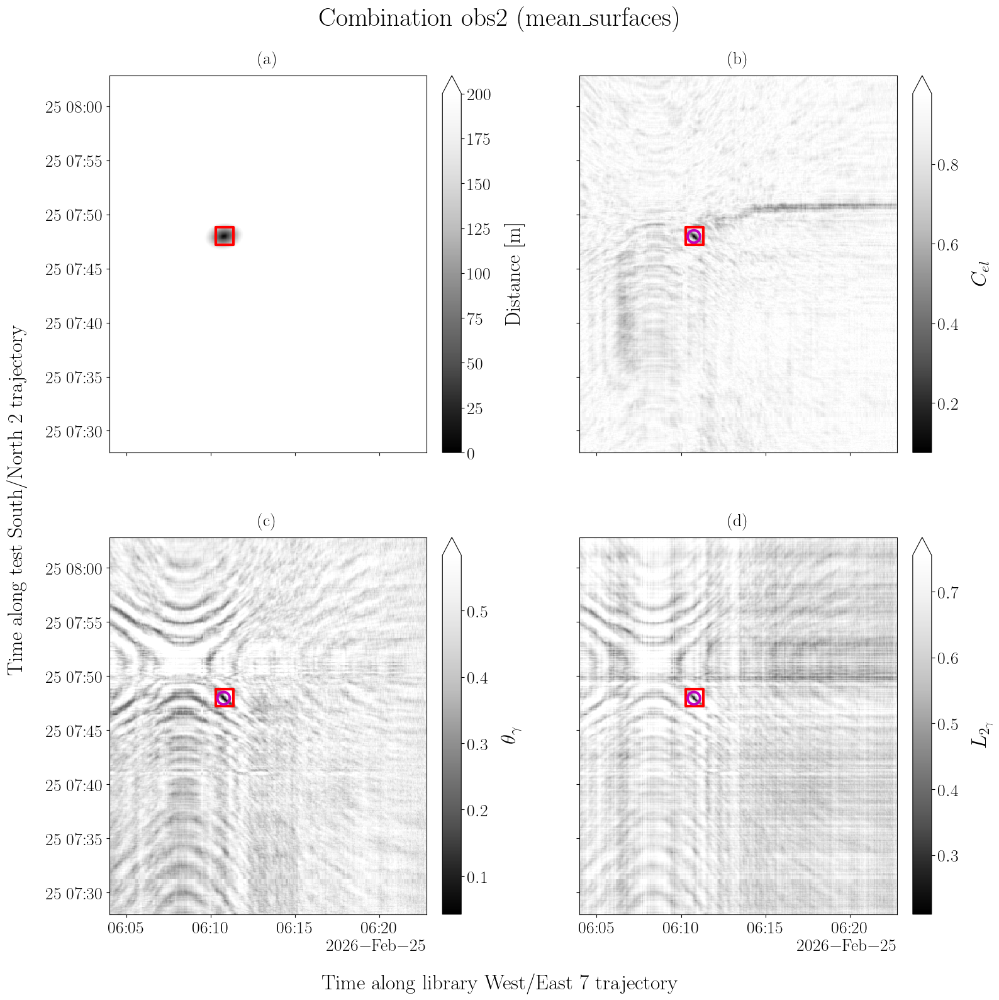

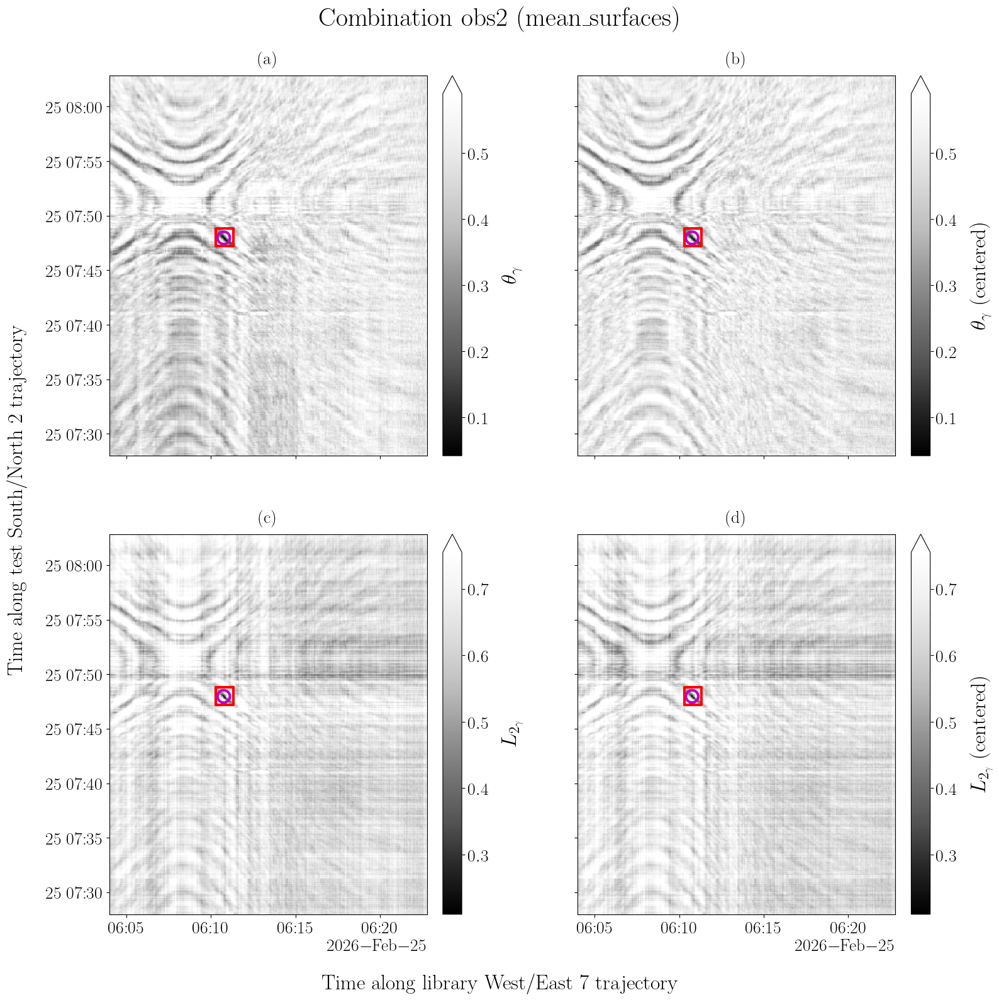

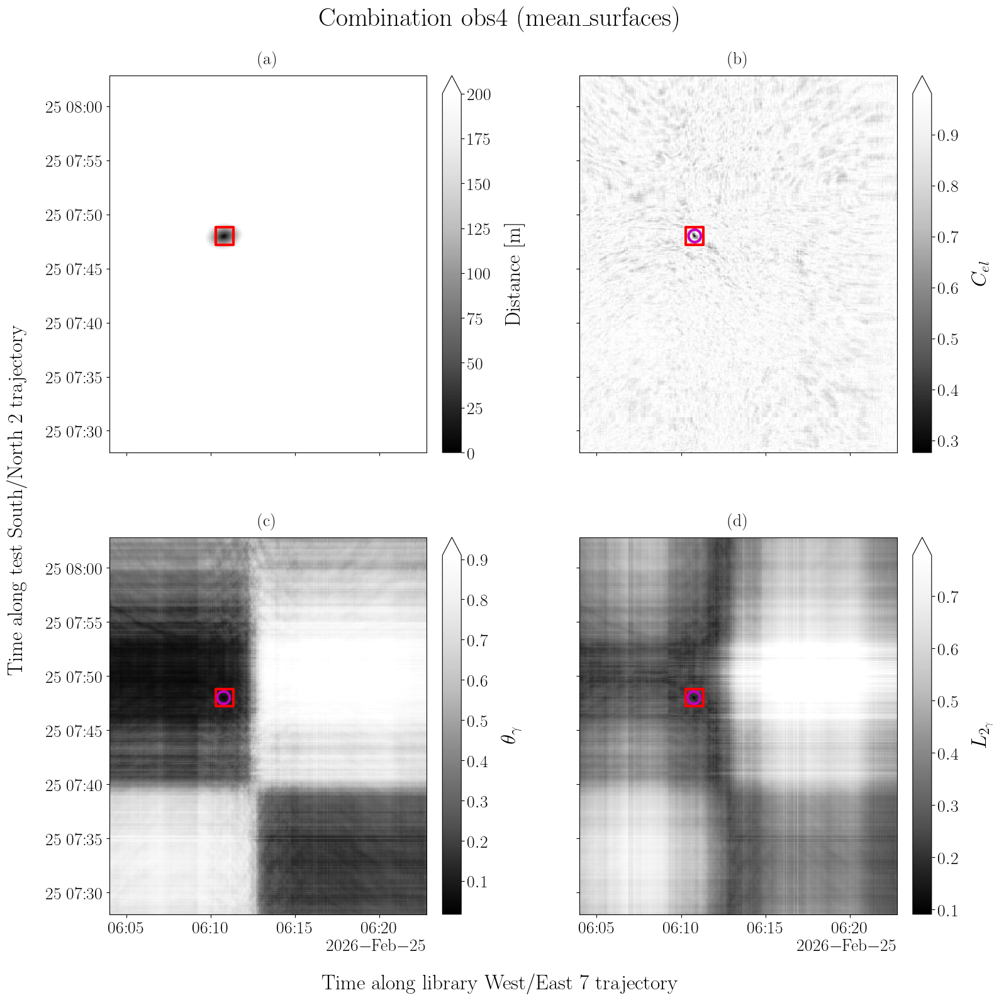

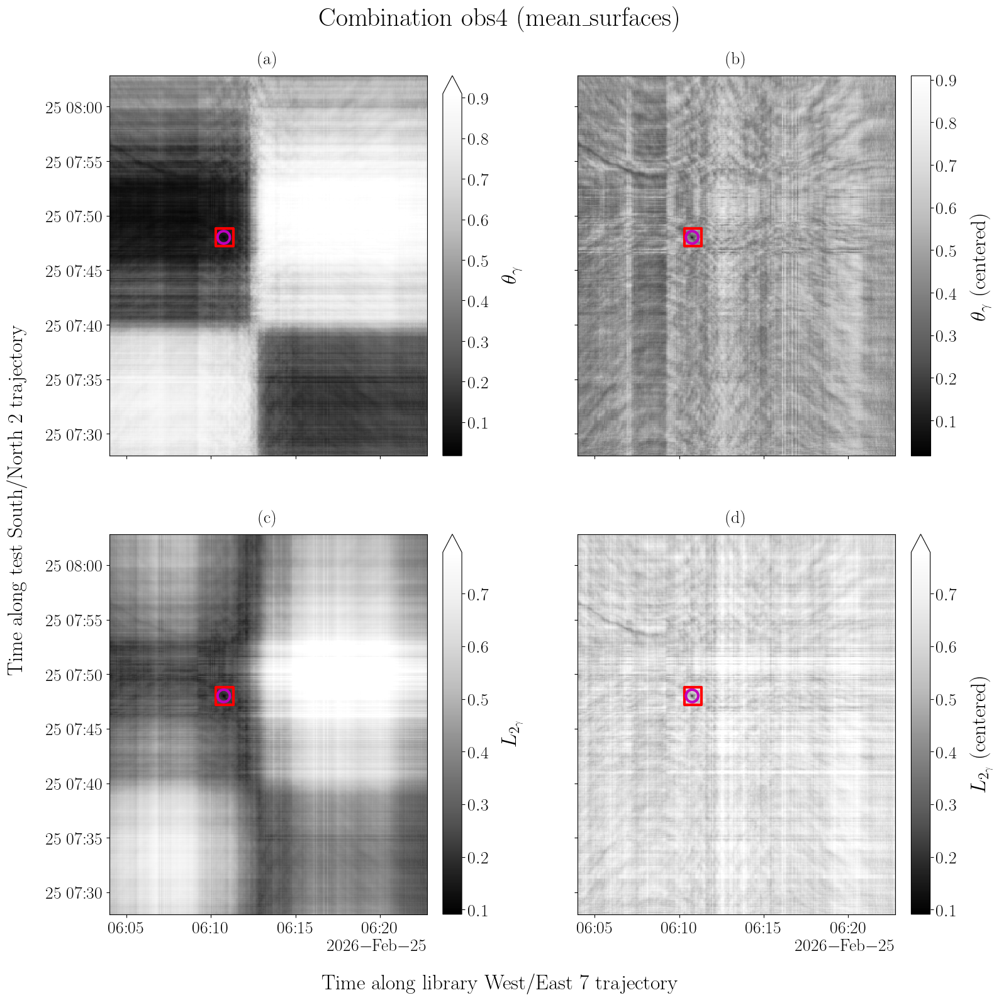

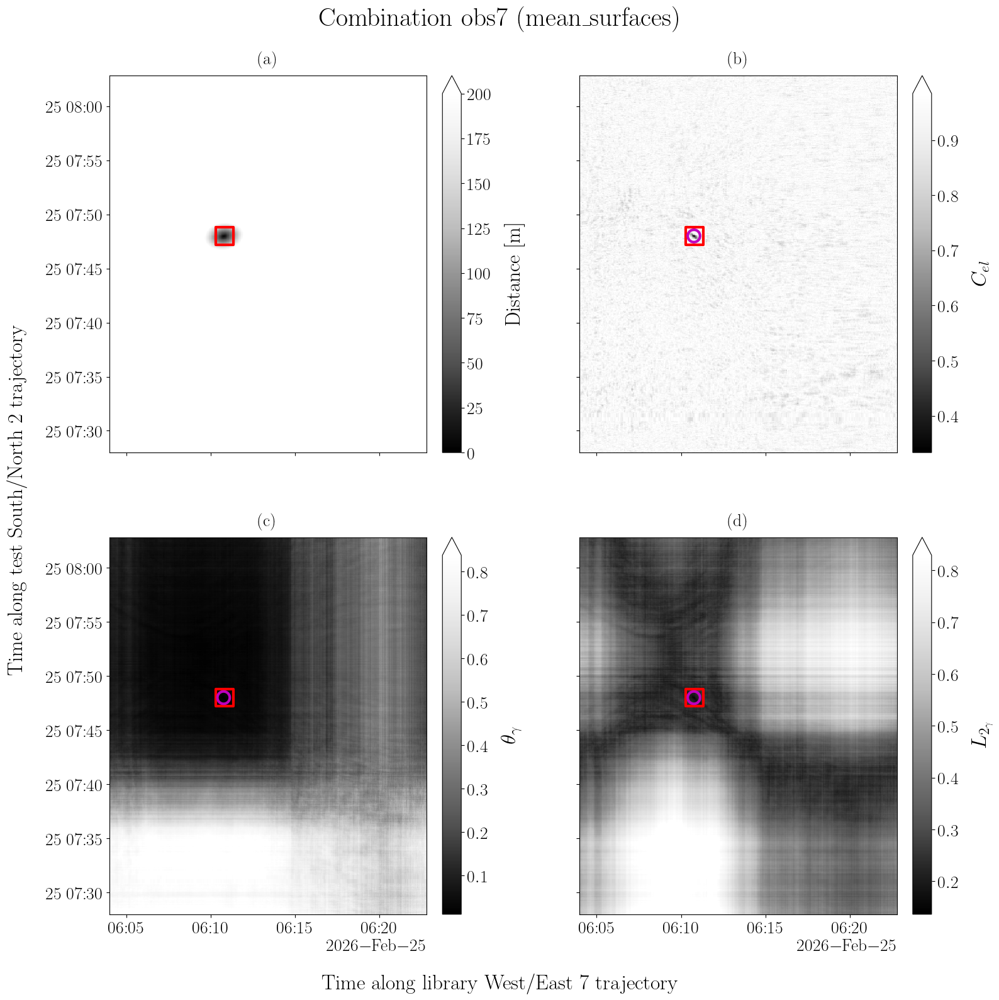

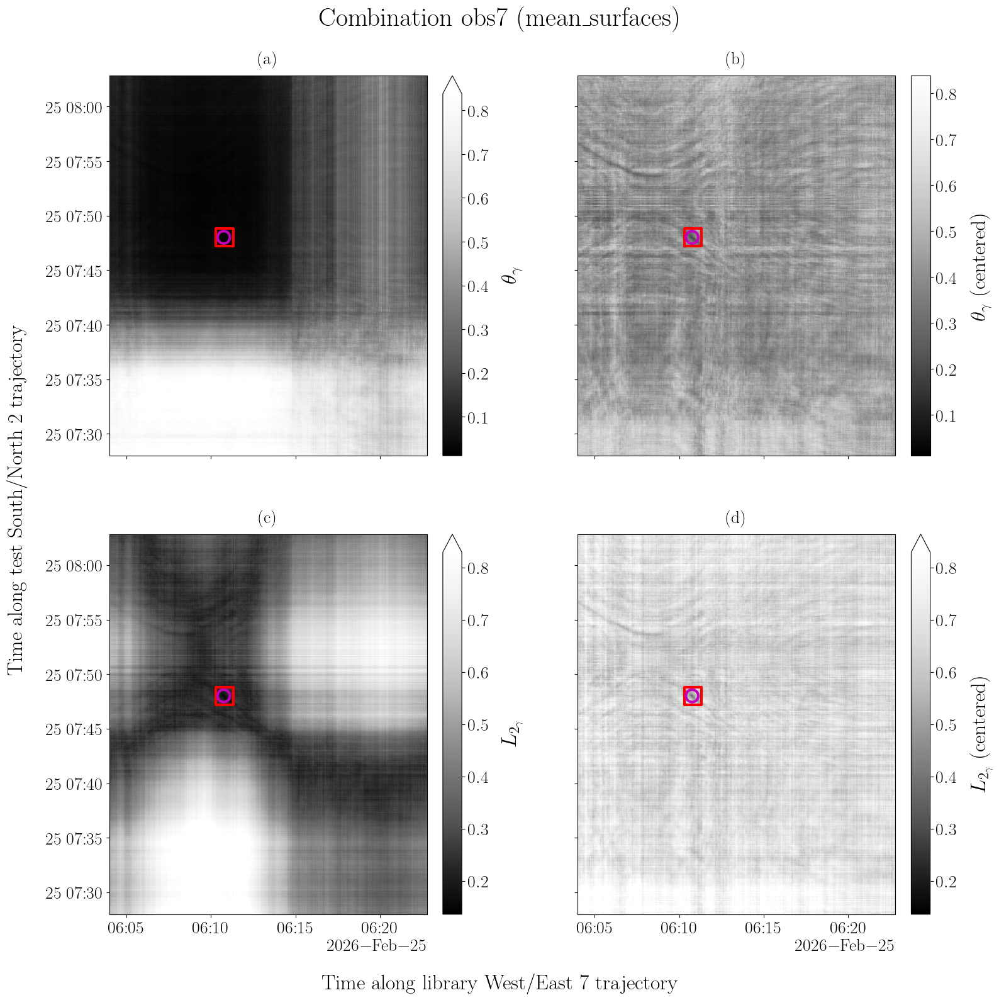

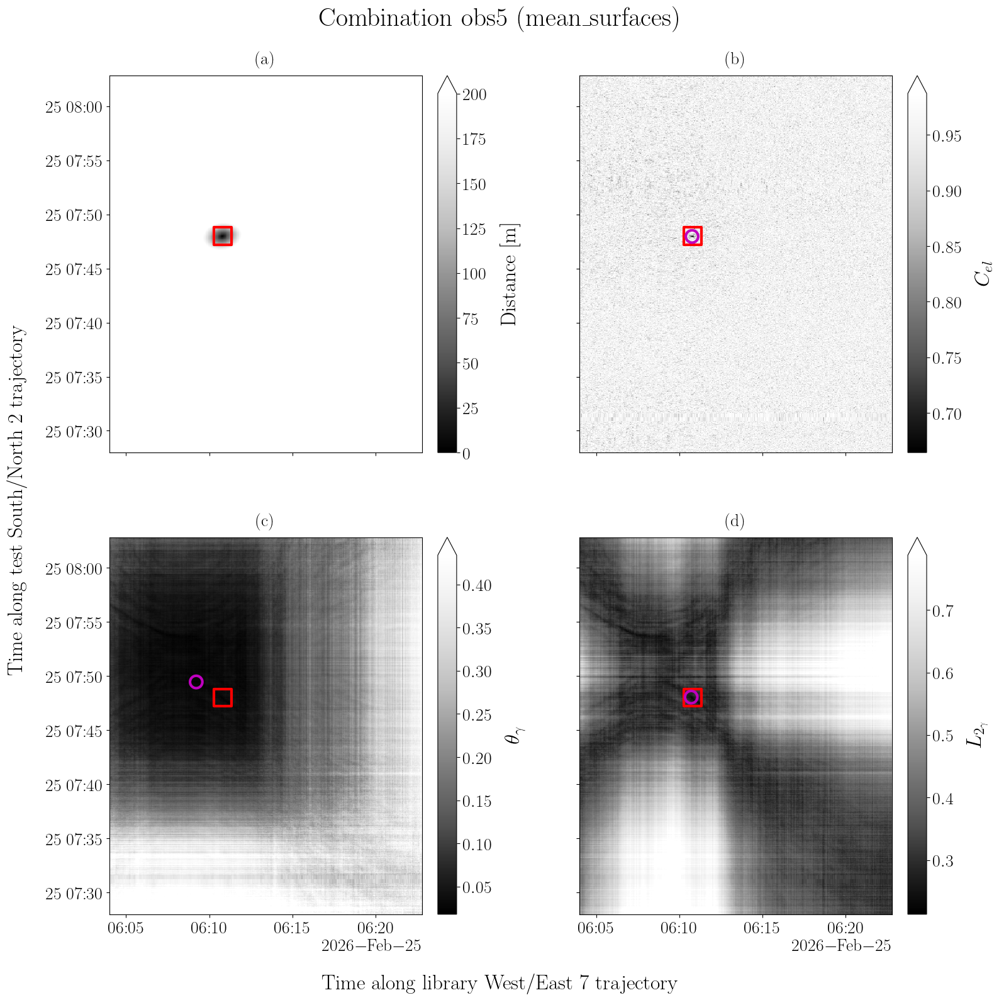

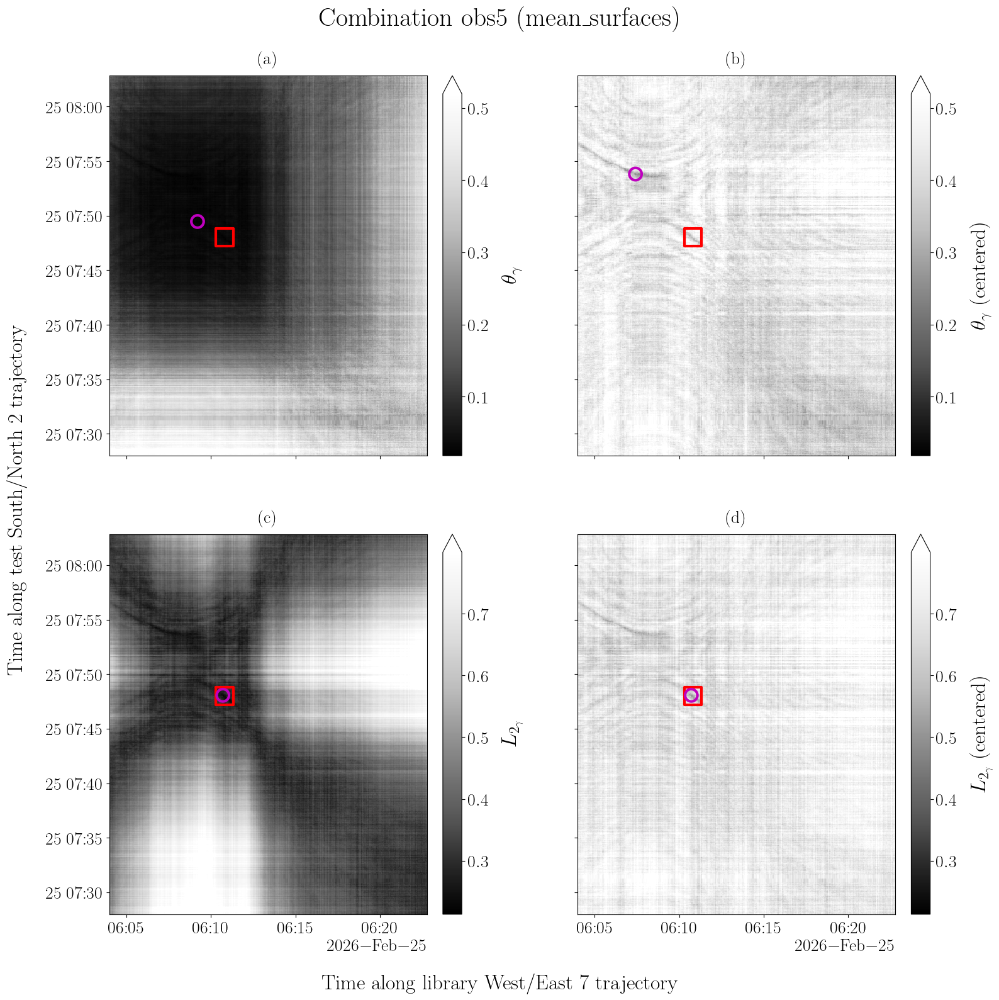

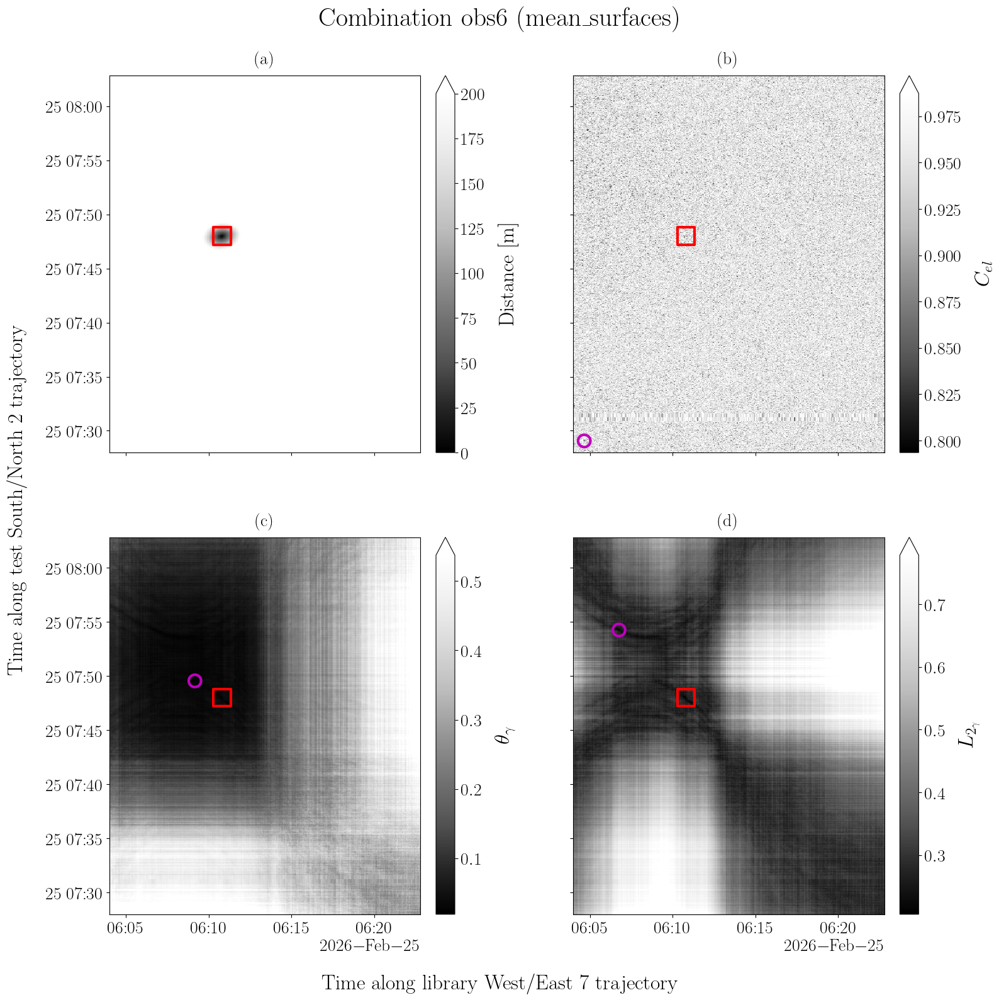

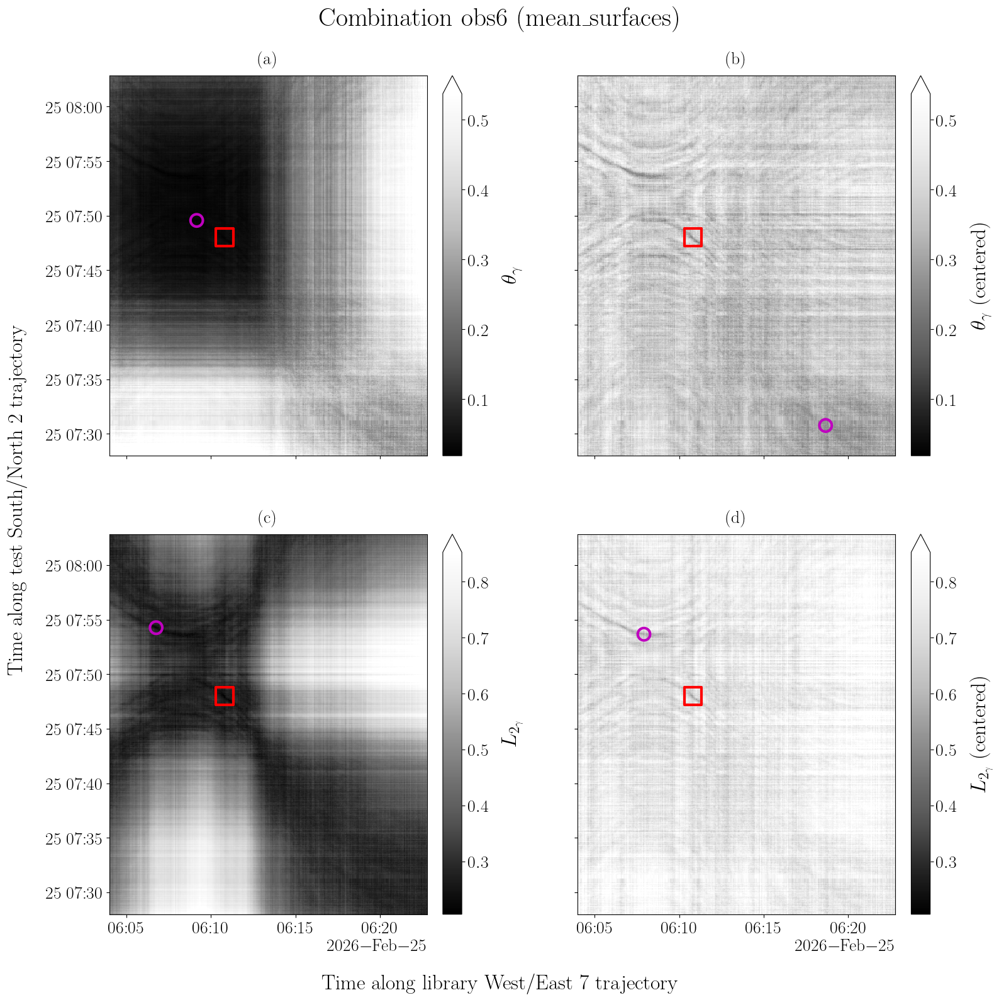

In [23]:
# ======================================================================================================================
# Ambiguity surfaces of the comparisons, for the combinations of receivers
# ======================================================================================================================
if plot_ambiguity or plot_gamma_comparison:
    log("Step 7 - Ambiguity surfaces of the combinations of receivers")

    # Combinations to plot: all those studied, or an explicit selection
    if combinations_to_plot is None:
        combinations_plotted = combinations
    else:
        combinations_plotted = enumerate_rcv_combinations(
            available_rcv_ids,
            sizes=None,
            combinations=combinations_to_plot,
            max_combinations=max_combinations,
        )

    n_figures = (
        len(datasets_mfp)
        * len(combinations_plotted)
        * (int(plot_ambiguity) + int(plot_gamma_comparison))
    )
    if n_figures > max_ambiguity_figures:
        raise ValueError(
            f"{n_figures} ambiguity figures requested ({len(datasets_mfp)} comparison(s) x "
            f"{len(combinations_plotted)} combination(s)), above max_ambiguity_figures = "
            f"{max_ambiguity_figures}: select fewer test sections, library sections or combinations "
            "(test_sections, library_sections, combinations_to_plot) or raise the limit."
        )
    log(f"{n_figures} figure(s)", level=1)

    for (library_name, event_name), ds_mfp in datasets_mfp.items():
        log(f"Library '{library_name}' x test section '{event_name}'", level=2)

        # Names displayed on the axes
        try:
            library_display_name = (
                f"library {section_name_of(portion.position[library_name])}"
            )
        except KeyError:
            # The orientation / identifier of the section are not stored: use its label
            library_display_name = f"library {library_name}"
        try:
            event_display_name = f"test {section_name_of(portion.position[event_name])}"
        except KeyError:
            # The orientation / identifier of the section are not stored: use its label
            event_display_name = f"test section {event_name}"

        # # One folder per comparison
        # save_ambiguity_figure = make_figure_saver(
        #     os.path.join(
        #         ROOT_IMG_PORTION_RESULTS_TEST,
        #         "ambiguity",
        #         f"{library_name}_{event_name}",
        #     ),
        #     log,
        # )

        for rcv_combination in combinations_plotted:
            slug = format_rcv_combination(rcv_combination, sep="_")

            if plot_ambiguity:
                fig = plot_combined_intersection_ambiguity(
                    ds_mfp,
                    rcv_combination,
                    library_display_name,
                    event_display_name,
                    method=combination_method,
                    cmap=ambiguity_cmap,
                    max_quantile=ambiguity_max_quantile,
                    metrics=ambiguity_metrics,
                    d_real_vmax=ambiguity_d_real_vmax,
                )
                # save_ambiguity_figure(
                #     fig, ambiguity_figure_filename(ambiguity_metrics, slug)
                # )

            if plot_gamma_comparison:
                fig = plot_combined_intersection_gamma_comparison(
                    ds_mfp,
                    rcv_combination,
                    library_display_name,
                    event_display_name,
                    method=combination_method,
                    cmap=ambiguity_cmap,
                    max_quantile=ambiguity_max_quantile,
                )
                # save_ambiguity_figure(fig, f"mfp_gamma_centered_comparison_{slug}.png")

# ======================================================================================================================
# Close the file
# ======================================================================================================================
portion.close()
log("Done (the portion file is not modified)")

On peut clairement observer la structure en damier des figures d'ambiguïté pour les OBS 4 et 7. Cette structure n'est pas observable pour l'OBS 2 situé proche de l'OBS de référence 1. 

Cette structure particulière disparait dans le cas où l'on centre $\gamma$  : 


$$
\gamma_{\text{centered}}(f) = \gamma(f) - < \gamma >_f 
$$

de telle sorte que

$$
< \gamma_{\text{centered}} >_f = 0 
$$

# Explication de la forme de la structure observée

La structure en damier observable traduit les variations de niveaux moyens de gamma en fonction de la position de la source. Pour s'en convaincre on peut ajouter aux surfaces d'ambiguïté la position des CPA de l'OBS utilisé.  

## Calcul de la distance de la source aux récepteurs 

In [24]:
def get_dist_src_rcv(src_lon, src_lat, rcv_lon, rcv_lat):
    from pyproj import Geod
    geod = Geod(ellps="WGS84")

    # Cast the rcv position to the shape of the src positions
    lon_rcv = np.full(src_lon.size, rcv_lon)
    lat_rcv = np.full(src_lat.size, rcv_lat)

    # Compute geodesic distance
    _, _, horizontal_distance = geod.inv(
        lons1=src_lon, lats1=src_lat, lons2=lon_rcv, lats2=lat_rcv
    )

    return horizontal_distance

def get_distance_src_to_rcv(ds_mfp_intersection):
    # Library
    lib_src_lon = ds_mfp_intersection.library_lon.values
    lib_src_lat = ds_mfp_intersection.library_lat.values
    # Event
    event_src_lon = ds_mfp_intersection.event_lon.values
    event_src_lat = ds_mfp_intersection.event_lat.values

    dist_lib = []
    dist_event = []
    for rcv_id in ds_mfp_intersection.rcv_id.values:

        rcv_lon_i = ds_mfp_intersection.rcv_lon.sel(rcv_id=rcv_id)
        rcv_lat_i = ds_mfp_intersection.rcv_lat.sel(rcv_id=rcv_id)

        d_lib = get_dist_src_rcv(lib_src_lon, lib_src_lat, rcv_lon_i, rcv_lat_i)
        d_event = get_dist_src_rcv(event_src_lon, event_src_lat, rcv_lon_i, rcv_lat_i)

        dist_lib.append(d_lib)
        dist_event.append(d_event)

    ds_mfp_intersection["distance_lib_rcv"] = (["rcv_id", "library_datetime"], np.asarray(dist_lib))
    ds_mfp_intersection["distance_event_rcv"] = (["rcv_id", "event_datetime"], np.asarray(dist_event))

In [25]:
ds_mfp_intersection = portion_mfp.mfp_intersection.oe7.sn2.to_dataset()
get_distance_src_to_rcv(ds_mfp_intersection)

In [26]:
ds_mfp_intersection

<xarray.Dataset> Size: 64MB
Dimensions:                 (rcv_id: 7, library_datetime: 376,
                             event_datetime: 685, rcv_id_feature: 5)
Coordinates:
  * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
  * library_datetime        (library_datetime) datetime64[ns] 3kB 2026-02-25T...
  * event_datetime          (event_datetime) datetime64[ns] 5kB 2026-02-25T07...
  * rcv_id_feature          (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs7'
Data variables: (12/16)
    rcv_lon                 (rcv_id) float64 56B ...
    rcv_lat                 (rcv_id) float64 56B ...
    rcv_immersion           (rcv_id) int16 14B ...
    library_lon             (library_datetime) float64 3kB 5.962 5.962 ... 5.922
    library_lat             (library_datetime) float64 3kB 43.02 43.02 ... 43.02
    event_lon               (event_datetime) float64 5kB 5.947 5.947 ... 5.949
    ...                      ...
    d_L2_gamma              (rcv_id_feature, library_datetime, event_datetime) float64 10MB ...
    d_dcf                   (rcv_id_feature, library_datetime, event_datetime) float64 10MB ...
    d_theta_gamma_centered  (rcv_id_feature, library_datetime, event_datetime) float64 10MB ...
    d_L2_gamma_centered     (rcv_id_feature, library_datetime, event_datetime) float64 10MB ...
    distance_lib_rcv        (rcv_id, library_datetime) float64 21kB 1.004e+03...
    distance_event_rcv      (rcv_id, event_datetime) float64 38kB 3.647e+03 ....
Attributes:
    description:               MFP result for a library section and an event
    campagne:                  ACOUPLANE
    section1:                  oe7
    section2:                  sn2
    library_acquisition_mode:  active
    event_acquisition_mode:    active
    reference_receiver:        obs1
    obs_position:              OBS position corrected using LMS inversion.
    obs_position_filepath:     C:\Users\baptiste.menetrier\Desktop\devPy\phd\...

## Visualisation distance source / récepteurs 

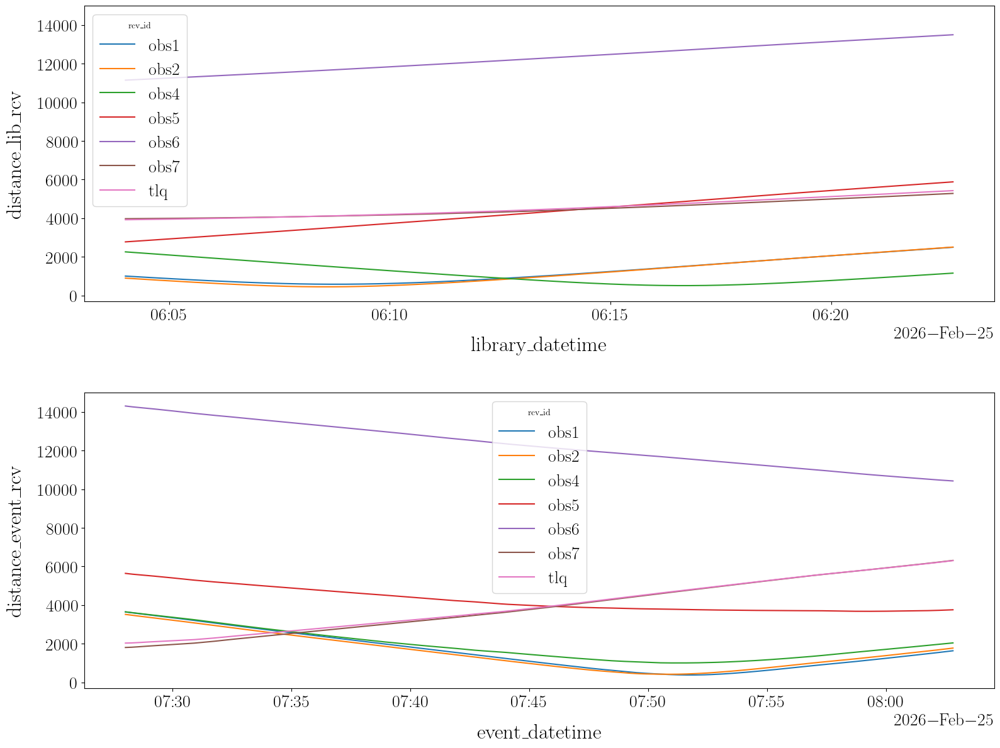

In [27]:
fig, axs = plt.subplots(2, 1, figsize=(16, 12), sharey=True)

ds_mfp_intersection.distance_lib_rcv.plot(x="library_datetime", hue="rcv_id", ax=axs[0])
ds_mfp_intersection.distance_event_rcv.plot(x="event_datetime", hue="rcv_id", ax=axs[1])

### Différence de distance 

$$
\xi = 10 \log_{10} \left(  \frac{r_i}{r_1} \right)

$$

(-5.0, 5.0)

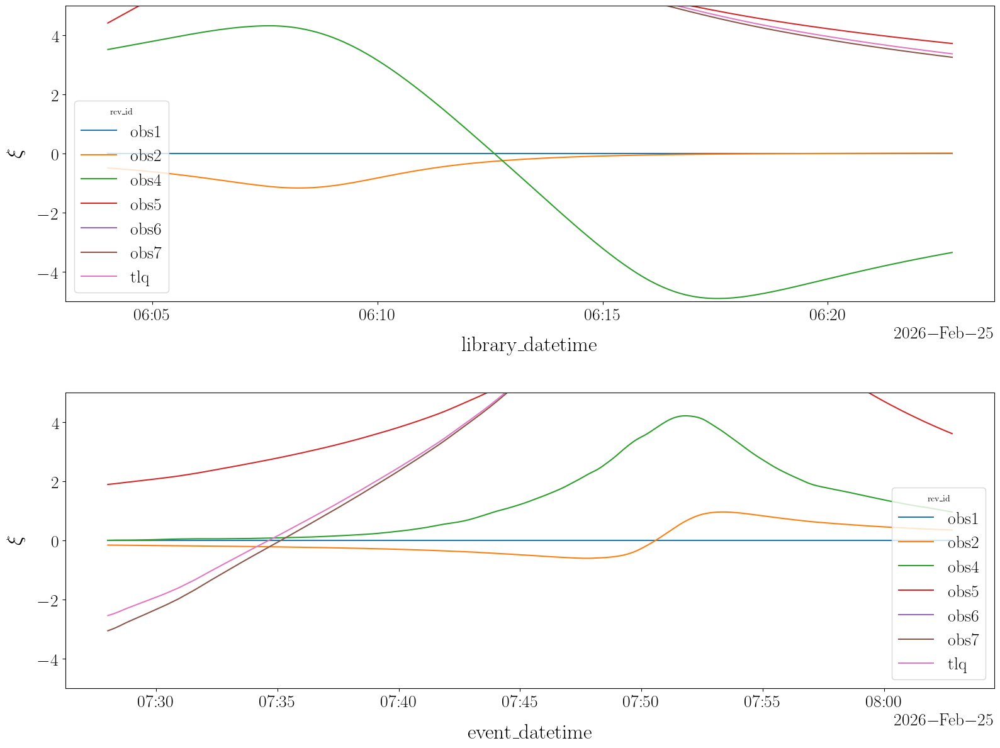

In [28]:
# Library
r_i_lib = ds_mfp_intersection.distance_lib_rcv
r_ref_lib = ds_mfp_intersection.distance_lib_rcv.sel(
    rcv_id=ds_mfp_intersection.reference_receiver
)
xi_lib = 10 * np.log10(r_i_lib / r_ref_lib)

# Event
r_i_event = ds_mfp_intersection.distance_event_rcv
r_ref_event = ds_mfp_intersection.distance_event_rcv.sel(
    rcv_id=ds_mfp_intersection.reference_receiver
)
xi_event = 10 * np.log10(r_i_event / r_ref_event)

# Plot
fig, axs = plt.subplots(2, 1, figsize=(16, 12), sharey=True)

xi_lib.plot(x="library_datetime", hue="rcv_id", ax=axs[0])
xi_event.plot(x="event_datetime", hue="rcv_id", ax=axs[1])

axs[0].set_ylabel(r"$\xi$")
axs[1].set_ylabel(r"$\xi$")

plt.ylim(-5, 5)

## Surface d'ambiguïté de $\xi$

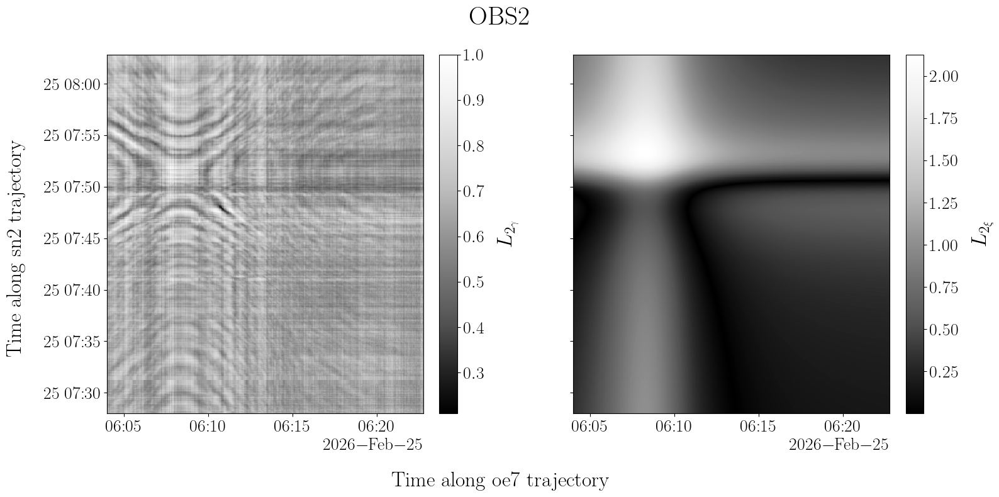

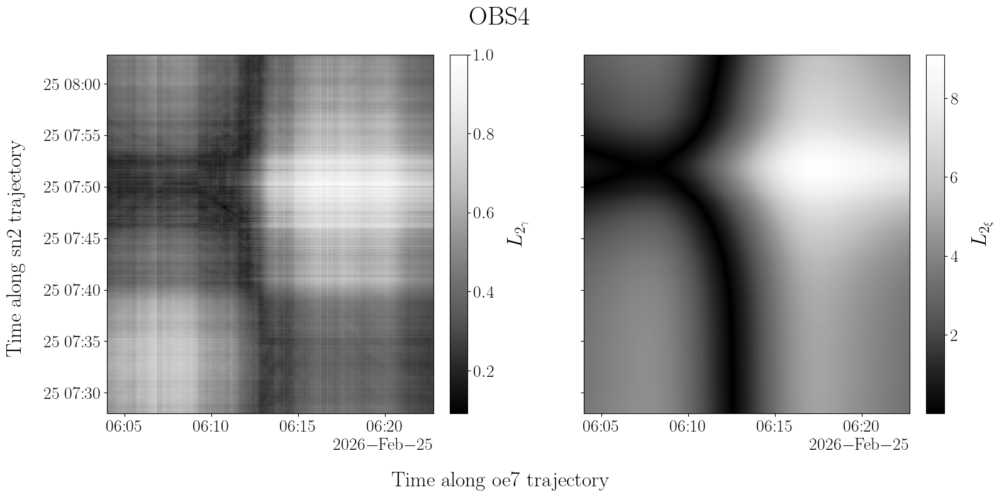

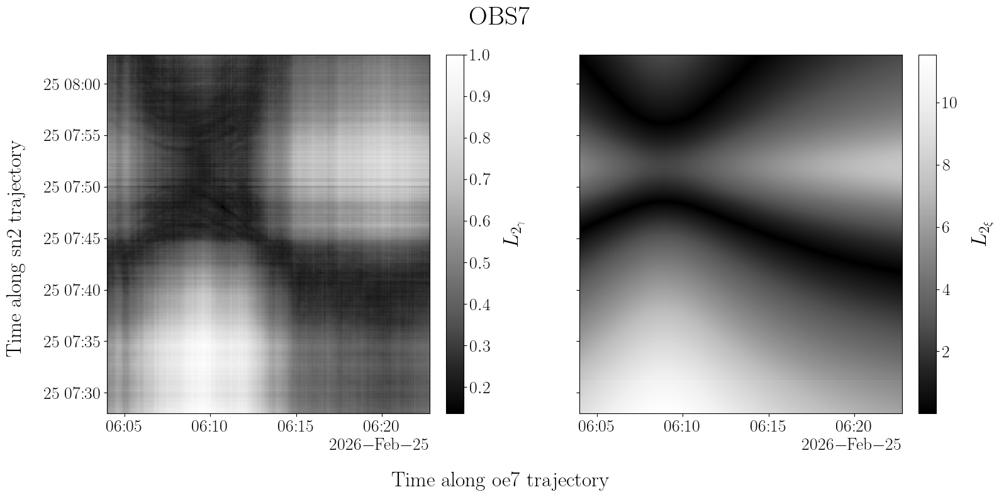

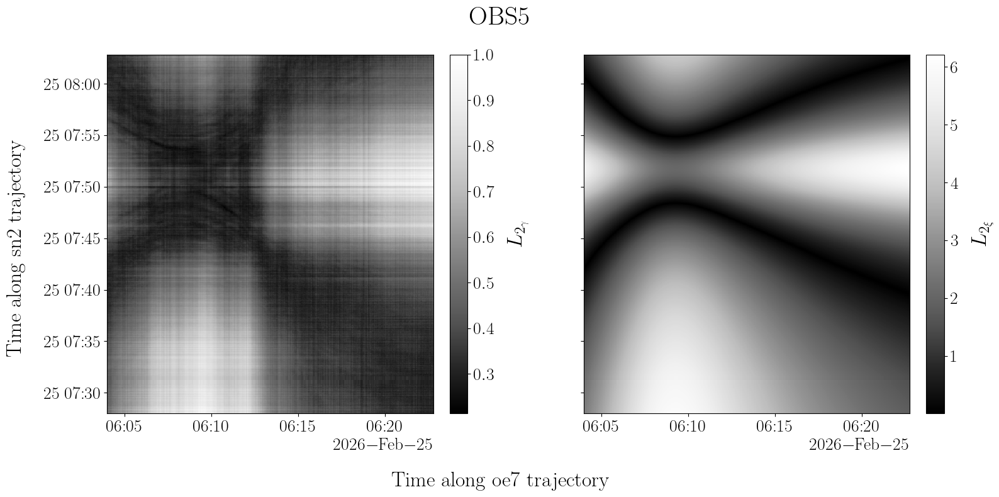

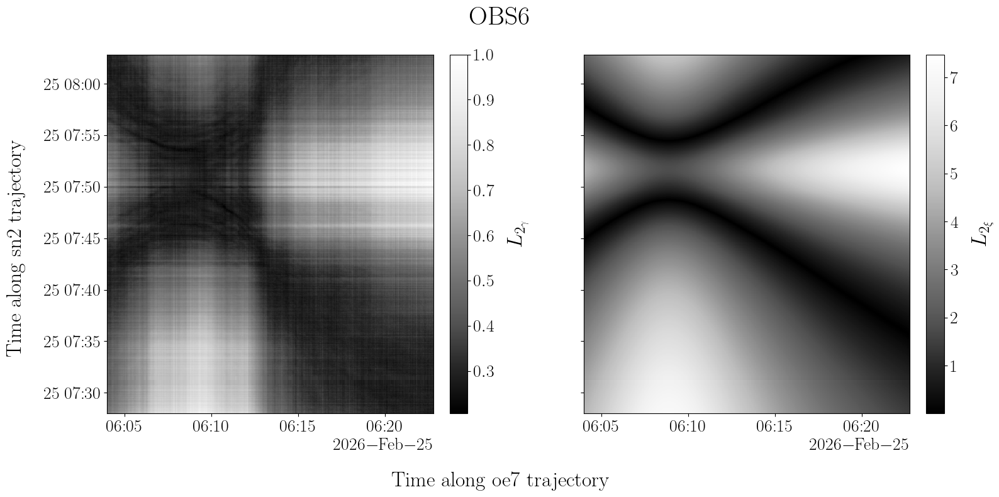

In [29]:
obs_ids_ = ["obs2", "obs4", "obs7", "obs5", "obs6"]
# obs_ids_ = ["obs2", "obs4", "obs7"]

for rcv_id in obs_ids_:
    xi_lib_rcv_id = xi_lib.sel(rcv_id=rcv_id)
    xi_event_rcv_id = xi_event.sel(rcv_id=rcv_id)

    d_lib_event = np.abs(
        xi_lib_rcv_id.values[np.newaxis, :] - xi_event_rcv_id.values[:, np.newaxis]
    )
    fig, axs = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
    ds_mfp_intersection.sel(rcv_id_feature=rcv_id).d_L2_gamma.plot(x="library_datetime", ax=axs[0], cmap=ambiguity_cmap)
    im = axs[1].pcolormesh(
        ds_mfp_intersection.library_datetime,
        ds_mfp_intersection.event_datetime,
        d_lib_event,
        cmap=ambiguity_cmap,
    )
    plt.colorbar(im, ax=axs[1], label=r"$L_{2_{\xi}}$")
    axs[0].set_xlabel("")
    axs[0].set_ylabel("")
    axs[0].set_title("")
    fig.suptitle(f"{rcv_id.upper()}")
    fig.supxlabel(f"Time along {ds_mfp_intersection.section1} trajectory")
    fig.supylabel(f"Time along {ds_mfp_intersection.section2} trajectory")

Text(0.02, 0.5, 'Time along sn2 trajectory')

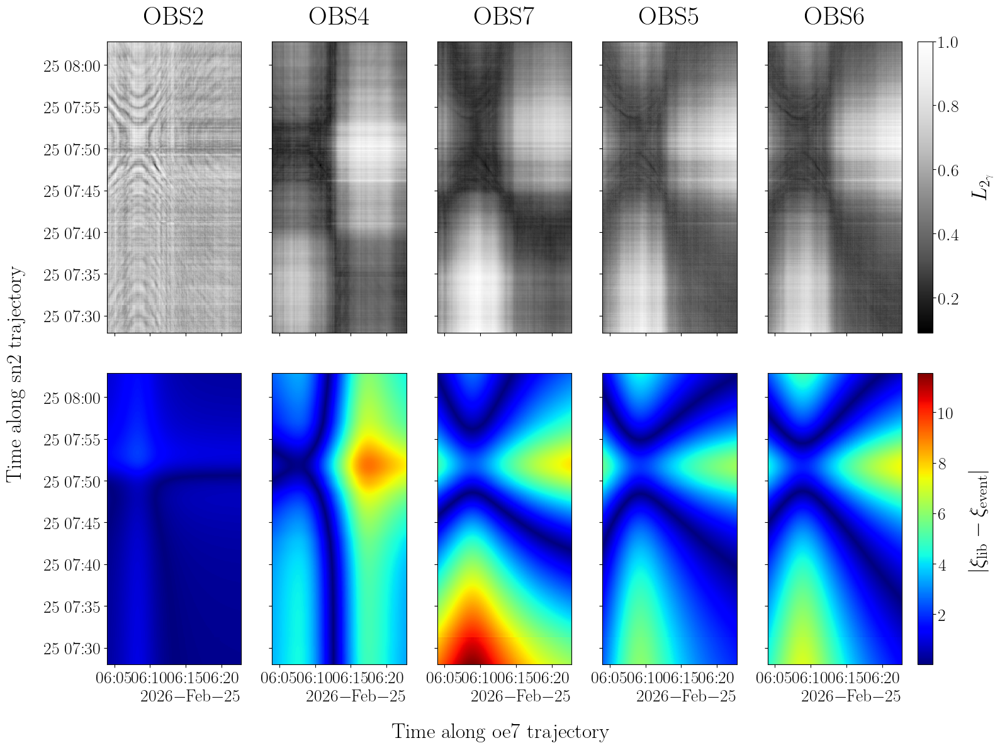

In [30]:
# obs_ids_ = ["obs2", "obs4", "obs7"]
obs_ids_ = ["obs2", "obs4", "obs7", "obs5", "obs6"]

fig, axs = plt.subplots(2, len(obs_ids_), figsize=(16, 12), sharex=True, sharey=True)

# Store the data to determine common color limits per row
d_lib_list = []
d_event_list = []

for rcv_id in obs_ids_:
    xi_lib_rcv_id = xi_lib.sel(rcv_id=rcv_id)
    xi_event_rcv_id = xi_event.sel(rcv_id=rcv_id)

    d_lib_event = np.abs(
        xi_lib_rcv_id.values[np.newaxis, :] - xi_event_rcv_id.values[:, np.newaxis]
    )

    d_lib_list.append(ds_mfp_intersection.sel(rcv_id_feature=rcv_id).d_L2_gamma)
    d_event_list.append(d_lib_event)


# Compute common color limits for each row
vmin_row0 = min(float(data.min()) for data in d_lib_list)
vmax_row0 = max(float(data.max()) for data in d_lib_list)

vmin_row1 = min(np.nanmin(data) for data in d_event_list)
vmax_row1 = max(np.nanmax(data) for data in d_event_list)


# Plot
for i, rcv_id in enumerate(obs_ids_):

    # First row
    im0 = d_lib_list[i].plot(
        x="library_datetime",
        ax=axs[0, i],
        cmap=ambiguity_cmap,
        vmin=vmin_row0,
        vmax=vmax_row0,
        add_colorbar=False,
    )

    # Second row
    im1 = axs[1, i].pcolormesh(
        ds_mfp_intersection.library_datetime,
        ds_mfp_intersection.event_datetime,
        d_event_list[i],
        cmap="jet",
        vmin=vmin_row1,
        vmax=vmax_row1,
        # shading="auto",
    )

    axs[0, i].set_title(f"{rcv_id.upper()}")


# Remove individual axis labels
for ax in axs.flatten():
    ax.set_xlabel("")
    ax.set_ylabel("")


# Add one common colorbar per row
fig.colorbar(
    im0,
    ax=axs[0, :].tolist(),
    location="right",
    label=r"$L_{2_\gamma}$",
    pad=0.02,
    fraction=0.04,
)

fig.colorbar(
    im1,
    ax=axs[1, :].tolist(),
    location="right",
    label=r"$|\xi_{\mathrm{lib}}-\xi_{\mathrm{event}}|$",
    pad=0.02,
    fraction=0.04,
)


# Figure labels
fig.supxlabel(f"Time along {ds_mfp_intersection.section1} trajectory")
fig.supylabel(f"Time along {ds_mfp_intersection.section2} trajectory")

# fig.tight_layout()

L'influence du terme $\xi$ sur la surface d'ambiguïté $L_{2_{\gamma}}$ est clairement visible. 

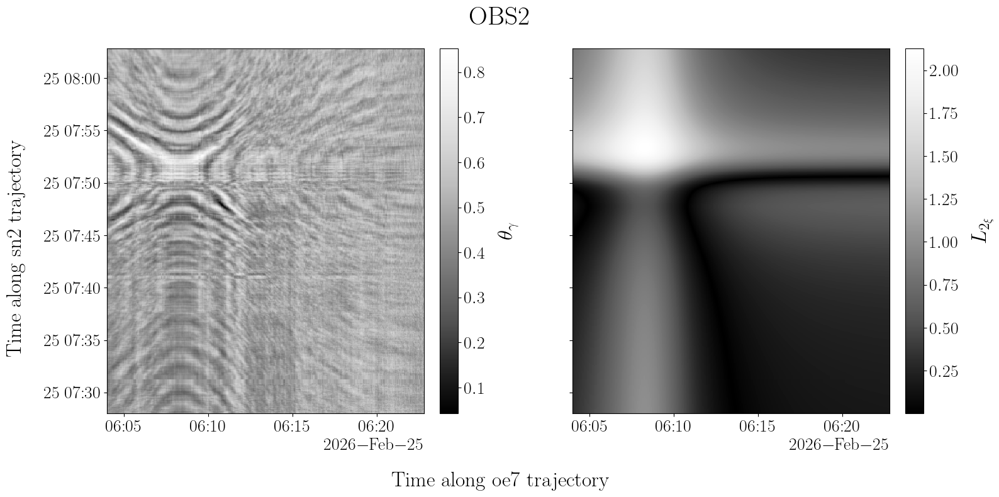

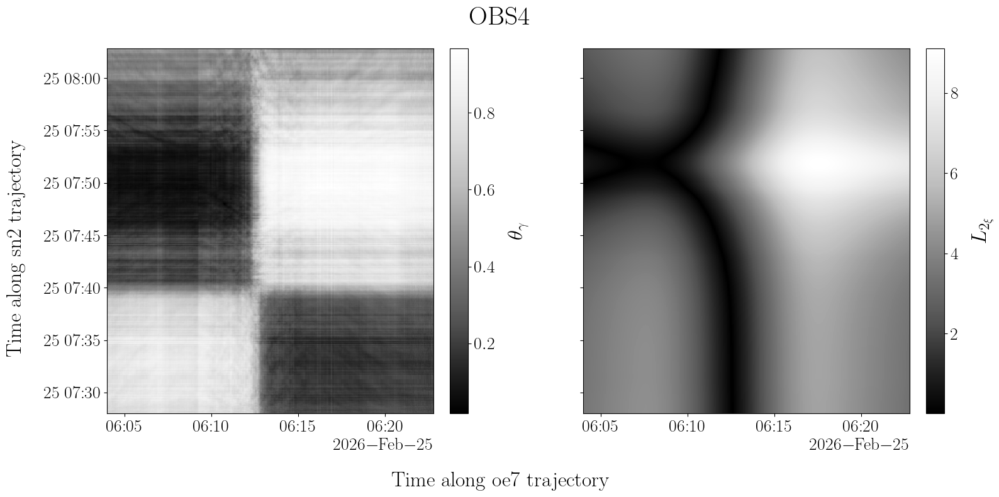

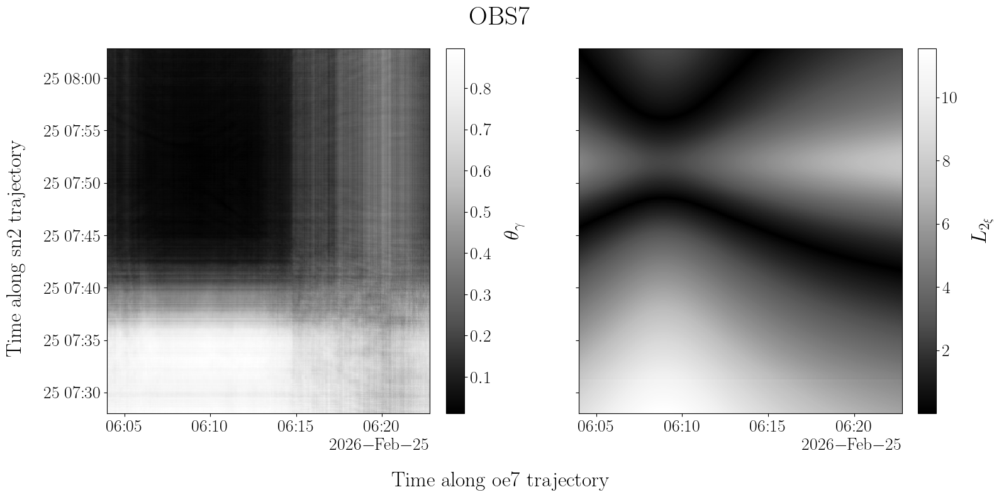

In [31]:
obs_ids_ = ["obs2", "obs4", "obs7"]
for rcv_id in obs_ids_:
    xi_lib_rcv_id = xi_lib.sel(rcv_id=rcv_id)
    xi_event_rcv_id = xi_event.sel(rcv_id=rcv_id)

    d_lib_event = np.abs(
        xi_lib_rcv_id.values[np.newaxis, :] - xi_event_rcv_id.values[:, np.newaxis]
    )
    fig, axs = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
    ds_mfp_intersection.sel(rcv_id_feature=rcv_id).d_theta_gamma.plot(x="library_datetime", ax=axs[0], cmap=ambiguity_cmap)
    im = axs[1].pcolormesh(
        ds_mfp_intersection.library_datetime,
        ds_mfp_intersection.event_datetime,
        d_lib_event,
        cmap=ambiguity_cmap,
    )
    plt.colorbar(im, ax=axs[1], label=r"$L_{2_{\xi}}$")
    axs[0].set_xlabel("")
    axs[0].set_ylabel("")
    axs[0].set_title("")
    fig.suptitle(f"{rcv_id.upper()}")
    fig.supxlabel(f"Time along {ds_mfp_intersection.section1} trajectory")
    fig.supylabel(f"Time along {ds_mfp_intersection.section2} trajectory")

La métrique $\theta_{\gamma}$ quant à elle est davantage liée au produit $\xi^{(\text{library})} \times \xi^{(\text{event})}$ comme on peut le voir ci-dessous. 

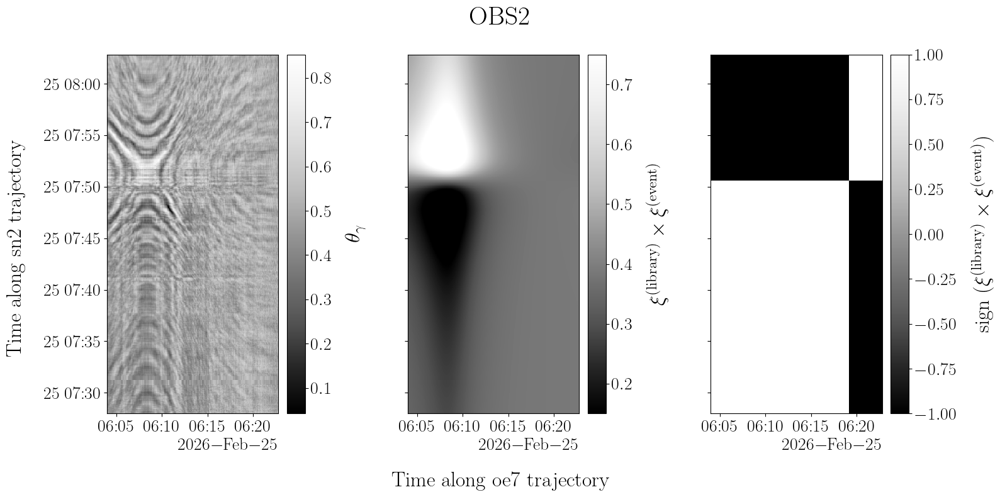

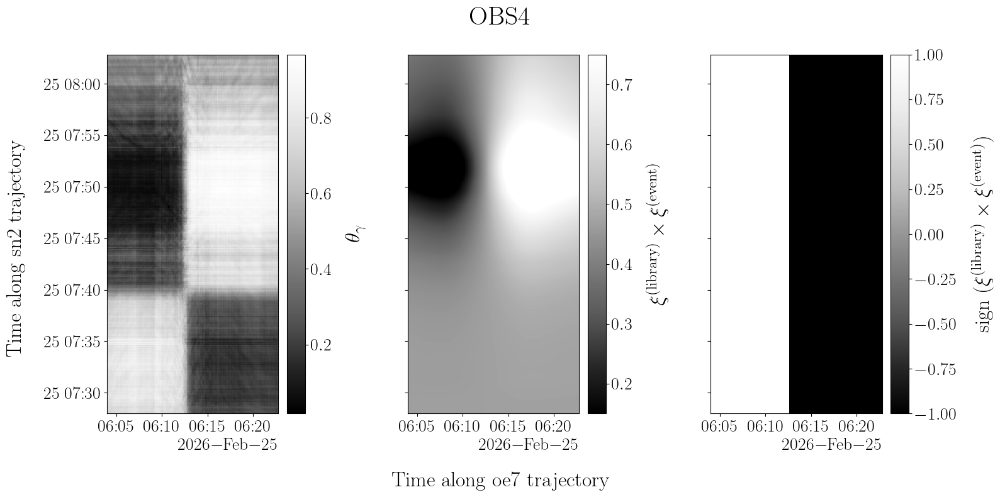

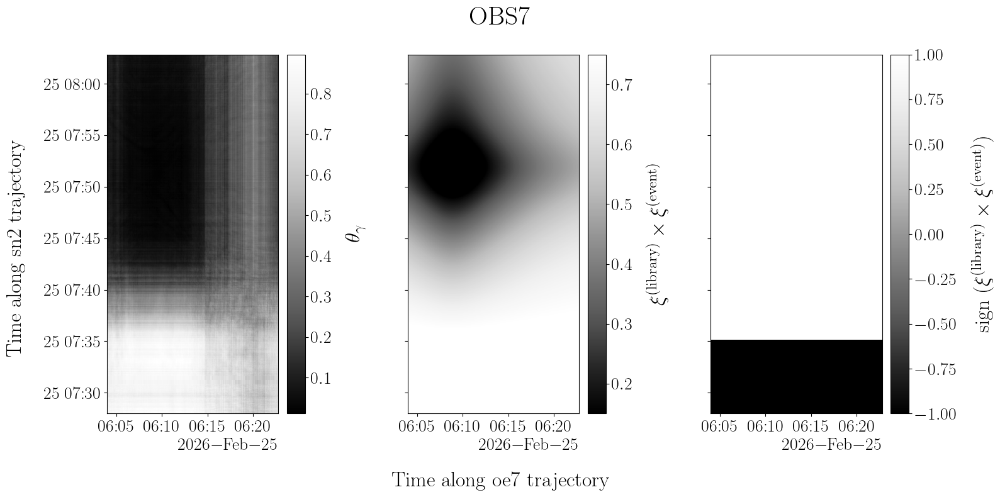

In [32]:
obs_ids_ = ["obs2", "obs4", "obs7"]
for rcv_id in obs_ids_:
    xi_lib_rcv_id = xi_lib.sel(rcv_id=rcv_id)
    xi_event_rcv_id = xi_event.sel(rcv_id=rcv_id)

    xi_lib_event_sign = np.sign(xi_lib_rcv_id.values[np.newaxis, :] * xi_event_rcv_id.values[:, np.newaxis])
    xi_lib_event_prod = xi_lib_rcv_id.values[np.newaxis, :] * xi_event_rcv_id.values[:, np.newaxis]
    xi_lib_event_prod = 1 - (xi_lib_event_prod - np.nanmin(xi_lib_event_prod)) / (
        np.nanmax(xi_lib_event_prod) - np.nanmin(xi_lib_event_prod)
    )

    fig, axs = plt.subplots(1, 3, figsize=(16, 8), sharex=True, sharey=True)
    ds_mfp_intersection.sel(rcv_id_feature=rcv_id).d_theta_gamma.plot(x="library_datetime", ax=axs[0], cmap=ambiguity_cmap)
    im = axs[1].pcolormesh(
        ds_mfp_intersection.library_datetime,
        ds_mfp_intersection.event_datetime,
        xi_lib_event_prod,
        cmap="Grays_r",
        vmin=0.15,
        vmax=0.75
    )
    plt.colorbar(
        im,
        ax=axs[1],
        label=r"$\xi^{(\text{library})} \times \xi^{(\text{event})}$",
        # label=r"sign $(\xi^{(\text{library})} \times \xi^{(\text{event})})$",
    )

    im = axs[2].pcolormesh(
        ds_mfp_intersection.library_datetime,
        ds_mfp_intersection.event_datetime,
        xi_lib_event_sign,
        cmap=ambiguity_cmap,
        # vmin=0.1,
        # vmax=0.8,
    )
    plt.colorbar(
        im,
        ax=axs[2],
        # label=r"$\xi^{(\text{library})} \times \xi^{(\text{event})}$",
        label=r"sign $(\xi^{(\text{library})} \times \xi^{(\text{event})})$",
    )

    axs[0].set_xlabel("")
    axs[0].set_ylabel("")
    axs[0].set_title("")
    fig.suptitle(f"{rcv_id.upper()}")
    fig.supxlabel(f"Time along {ds_mfp_intersection.section1} trajectory")
    fig.supylabel(f"Time along {ds_mfp_intersection.section2} trajectory")

In [33]:
# obs_ids_ = ["obs2", "obs4", "obs7"]
# for rcv_id in obs_ids_:
#     xi_lib_rcv_id = xi_lib.sel(rcv_id=rcv_id)
#     xi_event_rcv_id = xi_event.sel(rcv_id=rcv_id)

#     xi_lib_event_sign = np.sign(xi_lib_rcv_id.values[np.newaxis, :] * xi_event_rcv_id.values[:, np.newaxis])
#     xi_lib_event_prod = xi_lib_rcv_id.values[np.newaxis, :] * xi_event_rcv_id.values[:, np.newaxis]
#     # xi_lib_event_prod = 1 - (xi_lib_event_prod - np.nanmin(xi_lib_event_prod)) / (
#     #     np.nanmax(xi_lib_event_prod) - np.nanmin(xi_lib_event_prod)
#     # )
#     xi_lib_event_ = (
#         xi_lib_event_sign
#         * (xi_event_rcv_id.values[:, np.newaxis] - xi_lib_rcv_id.values[np.newaxis, :] )
#     )
#     xi_lib_event_ = (xi_lib_event_ - np.nanmin(xi_lib_event_)) / (
#         np.nanmax(xi_lib_event_) - np.nanmin(xi_lib_event_)
#     )

#     fig, axs = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
#     ds_mfp_intersection.sel(rcv_id_feature=rcv_id).d_theta_gamma.plot(x="library_datetime", ax=axs[0], cmap=ambiguity_cmap)
#     im = axs[1].pcolormesh(
#         ds_mfp_intersection.library_datetime,
#         ds_mfp_intersection.event_datetime,
#         xi_lib_event_,
#         cmap="Grays",
#         # vmin=0.1,
#         # vmax=0.8
#     )
#     plt.colorbar(
#         im,
#         ax=axs[1],
#         label=r"$\xi^{(\text{library})} \times \xi^{(\text{event})}$",
#         # label=r"sign $(\xi^{(\text{library})} \times \xi^{(\text{event})})$",
#     )

#     axs[0].set_xlabel("")
#     axs[0].set_ylabel("")
#     axs[0].set_title("")
#     fig.suptitle(f"{rcv_id.upper()}")
#     fig.supxlabel(f"Time along {ds_mfp_intersection.section1} trajectory")
#     fig.supylabel(f"Time along {ds_mfp_intersection.section2} trajectory")

# Analyse des SNRs 

In [ ]:
import scipy.signal as sp 

signal_duration_s = 3
offset_ms = 100

signal_duration_ms = int(round(signal_duration_s * 1000))
fs = portion.pressure.sn2.to_dataset().attrs["fs"]
n_samples_expected = int(signal_duration_s * fs)

ir_duration_s = 2
ir_duration_ms = int(round(ir_duration_s * 1000))   

n_samp_sig = int(ir_duration_s * fs)
n_samp_noise = int((signal_duration_s - ir_duration_s) * fs)

nfft = 2**int(np.ceil(np.log2(n_samp_sig)))
ff = np.fft.rfftfreq(nfft, d=1 / fs)  # (nfft // 2 + 1,)

In [ ]:
sxx_arr = []
snn_arr = []
snr_arr = []
for name, node in portion.pressure.children.items():
    ds_pos_section = portion.position[name].to_dataset()
    ds_pressure_section = node.to_dataset()
    ds_feature_section = portion.feature[name].to_dataset()

    valid_emission_dt = []
    # 2) Iterate over emissions
    for tir_emission_dt in ds_pos_section.src_datetime.values:
        tir_reception_dt = ds_pos_section["tir_reception_datetime"].sel(
            src_datetime=tir_emission_dt
        )

        # 3) Build list of signal_i
        noise_arr = []
        signal_arr = []
        cropped_signal = False
        for rcv_id_i in ds_pressure_section.obs_id.values:
            # Reception datetime for current rcv i
            tir_reception_dt_rcvi = tir_reception_dt.sel(rcv_id=rcv_id_i)

            # Select associated data window
            signal_i = ds_pressure_section[f"pressure_{rcv_id_i}"].sel(
                {
                    f"time_{rcv_id_i}": slice(
                        tir_reception_dt_rcvi.data - np.timedelta64(offset_ms, "ms"),
                        tir_reception_dt_rcvi.data
                        + np.timedelta64(signal_duration_ms - offset_ms, "ms"),
                    )
                }
            )

            if signal_i.size != n_samples_expected:
                cropped_signal = True
                break

            # Ensure signal is centered
            signal_i = signal_i - np.nanmean(signal_i)

            # Split into noise and signal
            sig = signal_i.values[:n_samp_sig]
            noise = signal_i.values[n_samp_sig : n_samp_sig + n_samp_noise]

            # Store in array
            signal_arr.append(sig)
            noise_arr.append(noise)

        if cropped_signal:
            continue

        valid_emission_dt.append(tir_emission_dt)
        signal_arr = np.asarray(signal_arr)  # (nrcv, nt)
        noise_arr = np.asarray(noise_arr)  # (nrcv, nt)

        # Compute noise and signal DSP
        x_rfft = np.fft.rfft(signal_arr, n=nfft, axis=1)  # (nrcv, nfft // 2 + 1)
        sxx = np.abs(x_rfft) ** 2  # (nrcv, nfft // 2 + 1)

        n_rfft = np.fft.rfft(noise_arr, n=nfft, axis=1)  # (nrcv, nfft // 2 + 1)
        snn = np.abs(n_rfft) ** 2  # (nrcv, nfft // 2 + 1)

        # Compute SNR
        snr = sxx / snn

        # Store in list
        sxx_arr.append(sxx)
        snn_arr.append(snn)
        snr_arr.append(snr)

        # Sxy_data.append(compute_cpsd_matrix(signal_arr, nfft, freq_band_mask))

In [ ]:
sxx_arr = np.asarray(sxx_arr)  # (n_emissions, nrcv, nfft // 2 + 1)
snn_arr = np.asarray(snn_arr)  # (n_emissions, nrcv, nfft // 2 + 1)
snr_arr = np.asarray(snr_arr)  # (n_emissions, nrcv, nfft // 2 + 1)

sxx_mean = sxx_arr.mean(axis=0)  # (nrcv, nfft // 2 + 1)
snn_mean = snn_arr.mean(axis=0)  # (nrcv, nfft // 2 + 1)
snr_mean = snr_arr.mean(axis=0)  # (nrcv, nfft // 2 + 1)

Text(0, 0.5, '$ \\frac{<S_{xx}>_t}{<S_{nn}>_t} $ [dB]')

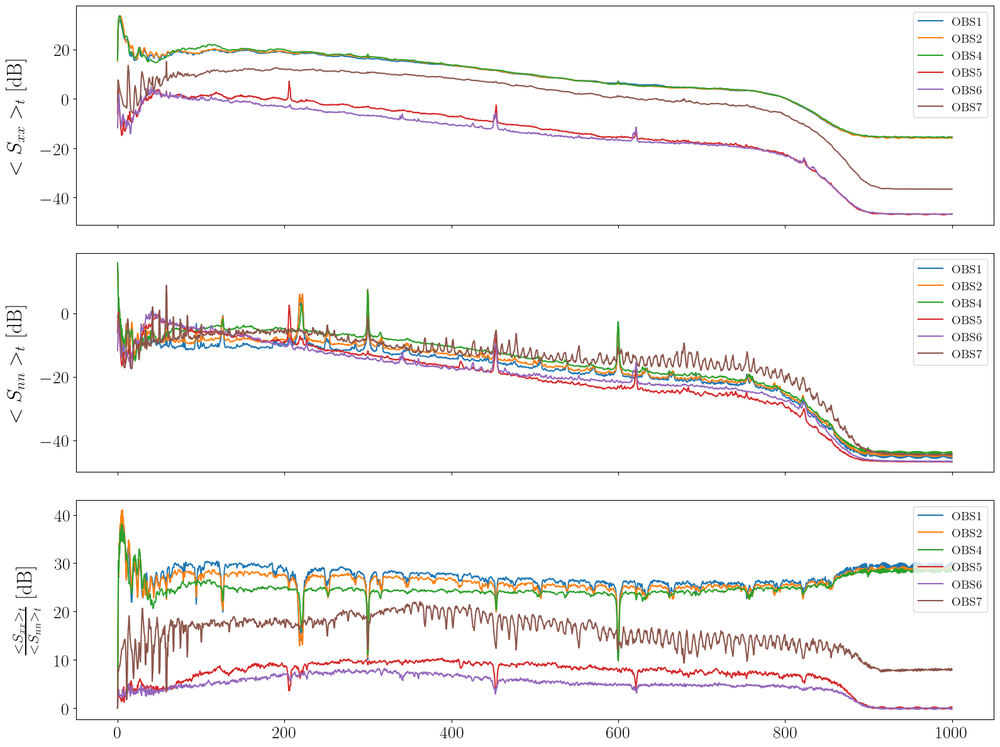

In [ ]:
# Plot
fig, axs = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

for rcv_id_i in ds_pressure_section.obs_id.values:
    axs[0].plot(
        ff,
        10 * np.log10(sxx_mean[ds_pressure_section.obs_id.values == rcv_id_i][0]),
        label=f"{rcv_id_i.upper()}",
    )
    axs[1].plot(
        ff,
        10 * np.log10(snn_mean[ds_pressure_section.obs_id.values == rcv_id_i][0]),
        label=f"{rcv_id_i.upper()}",
    )
    axs[2].plot(
        ff,
        # 10 * np.log10(snr_mean[ds_pressure_section.obs_id.values == rcv_id_i][0]),
        10 * np.log10(sxx_mean[ds_pressure_section.obs_id.values == rcv_id_i][0])
        - 10 * np.log10(snn_mean[ds_pressure_section.obs_id.values == rcv_id_i][0]),
        label=f"{rcv_id_i.upper()}",
    )

axs[0].legend(loc="upper right", fontsize=14)
axs[0].set_ylabel(r"$<S_{xx}>_t$ [dB]")
axs[1].legend(loc="upper right", fontsize=14)
axs[1].set_ylabel(r"$<S_{nn}>_t$ [dB]")
axs[2].legend(loc="upper right", fontsize=14)
# axs[2].set_ylabel(r"$\left < \frac{S_{xx}}{S_{nn}} \right >_t$ [dB]")
axs[2].set_ylabel(r"$ \frac{<S_{xx}>_t}{<S_{nn}>_t} $ [dB]")


# plt.xlim(0, 800)
# axs[2].set_ylim(30, 50)

**Note** : 

* Ce n'est pas évident de définir le SNR, l'ATALANTE est presque colocalisé avec la source, peut-on vraiment considérer que le signal du navire est du bruit ?

* Les raies visibles sur les OBS 5 et 6 les plus éloignés correspondent vraisemblablement aux raies d'un autre navire. Ces raies sont visibles sur les DSP du bruit et du signal. 

* Les raies visibles sur la DSP du bruit sur OBS 1, 2 et 4 correspondent vraisemblablement aux raies ATALANTE  



In [ ]:
# Slice the frequency band of interest
fmin_ = 0
fmax_ = 800
fslice = (ff >= fmin_) & (ff <= fmax_)
sxx_mean_fslice = sxx_mean[:, fslice]
ff_fslice = ff[fslice]

In [ ]:
dist_arr = []
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    d = ds_pos_section.src_rcv_geodesic_dist.values 
    dist_arr.append(d)  

dist_arr = np.hstack(dist_arr)  # (nrcv, nemissions)
mean_dist = dist_arr.mean(axis=1)  # (nrcv,)
mean_dist

array([ 2010.09063189,  1980.2476644 ,  1922.02812388,  4691.73181712,
       12654.83293094,  4124.07700879,  4213.96251456])

Absorption slope (dB/Hz): -0.00009


Text(0, 0.5, '$<S_{xx}>_t$ [dB]')

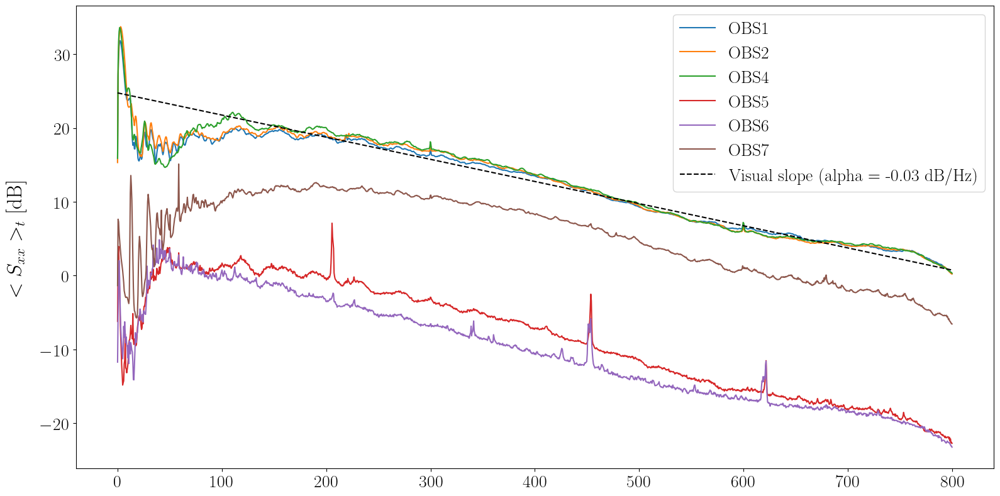

In [ ]:
fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True)
axs = np.atleast_1d(axs)
for rcv_id_i in ["obs1", "obs2", "obs4", "obs5", "obs6" , "obs7"]:
    axs[0].plot(
        ff_fslice,
        10
        * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == rcv_id_i][0]),
        label=f"{rcv_id_i.upper()}",
    )


# Add attenuation line for comparison
import arlpy
# Francois and Garrison
absorption = arlpy.uwa.absorption(
    ff_fslice, distance=mean_dist[0], temperature=27, salinity=35, depth=100, pH=8.1
)
absorption_dB = 20 * np.log10(absorption)

print(f"Absorption slope (dB/Hz): {(absorption_dB[-1] - absorption_dB[0])/(ff_fslice[-1] - ff_fslice[0]):.5f}")
# loss_abs = 10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == rcv_id_i][0])[1000] + absorption_dB
# plt.plot(
#     ff_fslice,
#     loss_abs,
#     label=f"FG Attenuation (r = {mean_dist[0]:.1f} m)",
#     color="k",
#     linestyle="--",
# )

# plt.xscale("log")

# Add line to estimate visualy the frequency slope
alpha_slop_dB_Hz = -0.03
ff_start = 200
idx_f = np.argmin(np.abs(ff_fslice - ff_start))
slope = (
    alpha_slop_dB_Hz * (ff_fslice - ff_start)
    + 10
    * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs1"][0])[idx_f]
)
plt.plot(
    ff_fslice,
    slope,
    label=f"Visual slope (alpha = {alpha_slop_dB_Hz} dB/Hz)",
    color="k",
    linestyle="--",
)

axs[0].legend()
axs[0].set_ylabel("$<S_{xx}>_t$ [dB]")

22.446108409452425
20.61167088205795
6.813081216336045


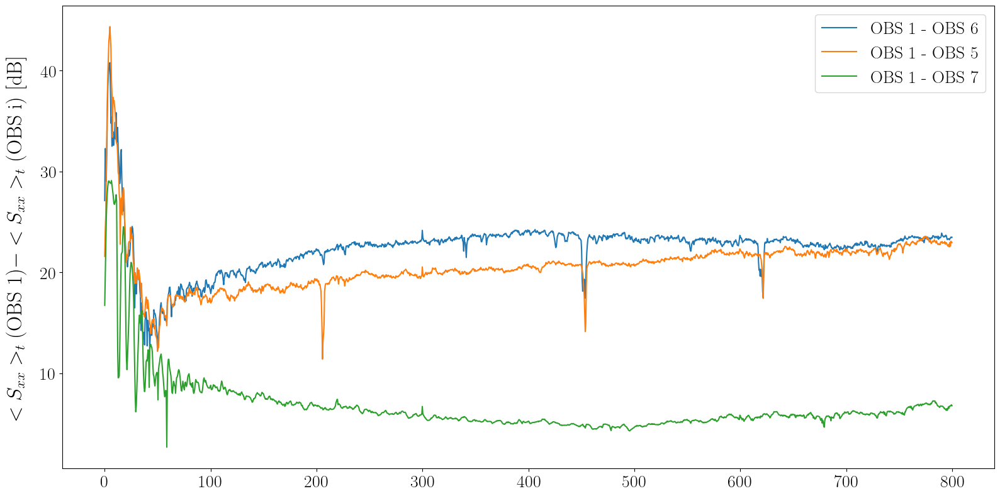

In [ ]:
fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True)
axs = np.atleast_1d(axs)
axs[0].plot(
    ff_fslice,
    10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs1"][0])
    - 10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs6"][0]),
    label=f"OBS 1 - OBS 6",
)
axs[0].plot(
    ff_fslice,
    10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs1"][0])
    - 10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs5"][0]),
    label=f"OBS 1 - OBS 5",
)
axs[0].plot(
    ff_fslice,
    10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs1"][0])
    - 10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs7"][0]),
    label=f"OBS 1 - OBS 7",
)
axs[0].legend()
axs[0].set_ylabel(r"$<S_{xx}>_t (\text{OBS 1}) - <S_{xx}>_t (\text{OBS i})$ [dB]")

print(
    np.mean(
        10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs1"][0])
        - 10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs6"][0])
    )
)
print(
    np.mean(
        10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs1"][0])
        - 10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs5"][0])
    )
)
print(
    np.mean(
        10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs1"][0])
        - 10 * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == "obs7"][0])
    )
)

Text(0, 0.5, '$<S_{xx}>_t$ [dB]')

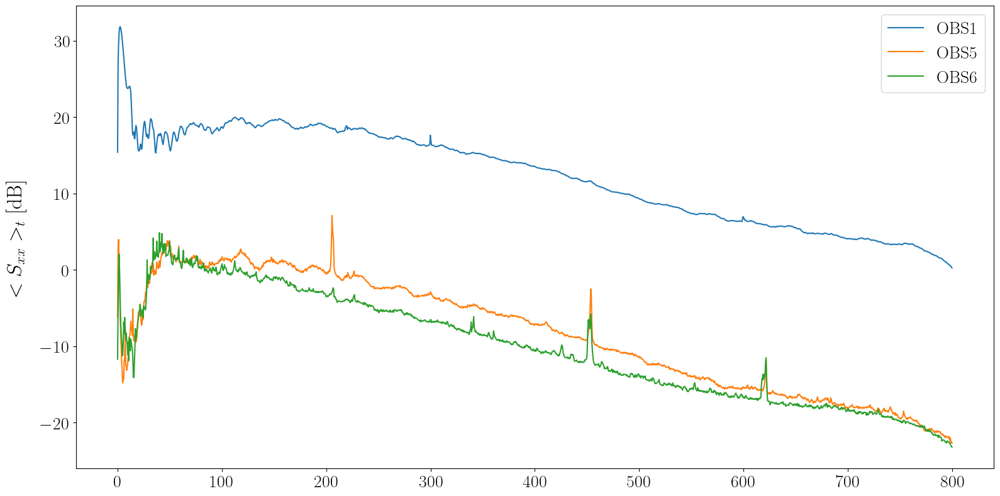

In [ ]:
fig, axs = plt.subplots(1, 1, figsize=(16, 8), sharex=True)
axs = np.atleast_1d(axs)
for rcv_id_i in ["obs1", "obs5", "obs6"]:
    axs[0].plot(
        ff_fslice,
        10
        * np.log10(sxx_mean_fslice[ds_pressure_section.obs_id.values == rcv_id_i][0]),
        label=f"{rcv_id_i.upper()}",
    )
axs[0].legend()
axs[0].set_ylabel("$<S_{xx}>_t$ [dB]")